#### Notebook 06 — Poverty Estimation and Survey Data Integration

This Notebook extends the MNO mobility project into a humanitarian analytics use case: investigating whether aggregated mobile-network activity can provide useful geographic indicators for poverty estimation.

The central question is:

`Can privacy-preserving, aggregated MNO mobility features contribute useful information to geographic poverty estimates when combined with household survey data?`

#### 1. Notebook setup and imports

In [19]:
# POVERTY ESTIMATION AND SURVEY DATA INTEGRATION

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from IPython.display import display

from sklearn.model_selection import (
    train_test_split,
    GroupShuffleSplit,
    GroupKFold,
    cross_validate
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import (
    RandomForestClassifier,
    RandomForestRegressor,
    HistGradientBoostingClassifier,
    HistGradientBoostingRegressor
)

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    f1_score,
    precision_score,
    recall_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

sns.set_theme(style="whitegrid", context="notebook")

# PROJECT PATHS

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_PATH = PROJECT_ROOT / "data" / "raw"

PROCESSED_PATH = PROJECT_ROOT / "data" / "processed"

EXTERNAL_PATH = PROJECT_ROOT / "data" / "external"

NOTEBOOK06_OUTPUT = (
    PROCESSED_PATH / "notebook_06"
)

NOTEBOOK06_OUTPUT.mkdir(
    parents=True,
    exist_ok=True
)

# INPUT FILES
MNO_DATA_FILE = (
    RAW_PATH / "MPD_sample_synthetic_ken_3000subs_full.csv"
)

CELL_VALIDATION_FILE = (
    PROCESSED_PATH
    / "notebook_02"
    / "cell_coordinate_validation.csv"
)

COUNTY_BOUNDARY_FILE = (
    EXTERNAL_PATH / "target_areas.geojson"
)


# CONFIGURATION
GRID_SIZE = 0.05

EARTH_RADIUS_KM = 6371.0088

POVERTY_LINE_MONTHLY = 3000

RANDOM_STATE = 42

MIN_SUBSCRIBERS_PER_ZONE = 5

print("Project root:", PROJECT_ROOT)

print("Notebook 06 output:", NOTEBOOK06_OUTPUT)

Project root: /Users/Apple/Documents/mno_mobility_intelligence_residence_and_population_displacement_inference
Notebook 06 output: /Users/Apple/Documents/mno_mobility_intelligence_residence_and_population_displacement_inference/data/processed/notebook_06


#### 2. Load and validate MNO data

In [20]:
# LOAD MNO DATA
df = pd.read_csv(
    MNO_DATA_FILE,
    dtype={
        "msisdn": "string",
        "cell_id": "string",
        "latitude": "float64",
        "longitude": "float64",
        "data_type": "category",
        "service": "category",
        "location_target": "category",
        "location_place": "category",
        "profile": "category",
        "record_profile": "category",
        "movement_profile": "category"
    },
    low_memory=False
)

cell_validation = pd.read_csv(
    CELL_VALIDATION_FILE,
    dtype={
        "msisdn": "string",
        "cell_id": "string",
        "latitude": "float64",
        "longitude": "float64",
        "data_type": "category",
        "service": "category",
        "location_target": "category",
        "location_place": "category",
        "profile": "category",
        "record_profile": "category",
        "movement_profile": "category"
    },
    low_memory=False
)


# VALIDATE SCHEMA

required_columns = [
    "msisdn",
    "datetime",
    "cell_id",
    "latitude",
    "longitude",
    "data_type"
]

missing_columns = (
    set(required_columns) - set(df.columns)
)

if missing_columns:
    raise ValueError(
        f"Missing MNO columns: {missing_columns}"
    )


df["datetime"] = pd.to_datetime(
    df["datetime"],
    errors="coerce"
)

df["latitude"] = pd.to_numeric(
    df["latitude"],
    errors="coerce"
)

df["longitude"] = pd.to_numeric(
    df["longitude"],
    errors="coerce"
)


print("Dataset shape:", df.shape)

print("Subscribers:", df["msisdn"].nunique())

print("Cells:", df["cell_id"].nunique())

print(
    "Observation period:",
    df["datetime"].min(),
    "to",
    df["datetime"].max()
)

Dataset shape: (1072608, 16)
Subscribers: 3000
Cells: 35956
Observation period: 2026-02-01 00:02:00 to 2026-02-28 23:59:00


#### 3. Apply coordinate quality checks

In [21]:
# VALIDATE CELL COORDINATES
if "coordinate_quality_flag" not in cell_validation.columns:
    raise ValueError(
        "coordinate_quality_flag missing from cell validation file"
    )

valid_cells = set(
    cell_validation.loc[
        cell_validation["coordinate_quality_flag"]
        == "acceptable",
        "cell_id"
    ]
)


df = df[
    df["cell_id"].isin(valid_cells)
].copy()


df = df.dropna(
    subset=[
        "msisdn",
        "datetime",
        "cell_id",
        "latitude",
        "longitude"
    ]
)


df = df[
    df["latitude"].between(-90, 90)
    &
    df["longitude"].between(-180, 180)
].copy()


print("Validated MNO records:", len(df))

print("Validated subscribers:", df["msisdn"].nunique())

print("Validated cells:", df["cell_id"].nunique())

Validated MNO records: 494850
Validated subscribers: 2997
Validated cells: 24986


In [22]:
df.head()

,msisdn,datetime,cell_id,latitude,longitude,data_type,service,location_target,location_place,movement_dist,movement_speed,is_robot,profile,tourist,record_profile,movement_profile
0,subscribers_00323,2026-02-01 01:23:00,33597,-1.267,36.915,CDR,2G,home,home,0.000,0.000,0,neutral,False,very_high,short
1,subscribers_00323,2026-02-01 03:55:00,33597,-1.267,36.915,CDR,2G,home,home,0.000,0.000,0,neutral,False,very_high,short
2,subscribers_00323,2026-02-01 06:53:00,33597,-1.267,36.915,CDR,2G,home,home,0.000,0.000,0,neutral,False,very_high,short
3,subscribers_00323,2026-02-01 07:52:00,33597,-1.267,36.915,CDR,2G,home,home,0.000,0.000,0,neutral,False,very_high,short
4,subscribers_00323,2026-02-01 09:07:00,31239,-1.271,36.900,CDR,2G,other,other,1.728,0.384,0,neutral,False,very_high,short


#### 4. Construct geographic zones

Use geographic aggregation rather than subscriber-level matching.

This is important because household survey data and MNO data should not be linked through individual subscriber identifiers.

In [ ]:
# ASSIGN GEOGRAPHIC GRID
mno = df.copy()

mno["latitude_zone"] = (
    np.floor(
        mno["latitude"] / GRID_SIZE
    ) * GRID_SIZE
)

mno["longitude_zone"] = (
    np.floor(
        mno["longitude"] / GRID_SIZE
    ) * GRID_SIZE
)

mno["geographic_zone"] = (
    mno["latitude_zone"].round(3).astype(str)
    + "_"
    + mno["longitude_zone"].round(3).astype(str)
)


print("Geographic zones:", mno["geographic_zone"].nunique())

display(
    mno[
        [
            "geographic_zone",
            "latitude_zone",
            "longitude_zone"
        ]
    ].drop_duplicates().head()
)

Geographic zones: 77


,geographic_zone,latitude_zone,longitude_zone
0,-1.3_36.9,-1.300,36.900
4,-1.3_36.85,-1.300,36.850
8,-1.3_36.8,-1.300,36.800
26,-1.35_36.9,-1.350,36.900
96,-1.15_36.95,-1.150,36.950


#### 5. Engineer geographic MNO features

Derive features from event counts and subscriber activity, not from simulator-generated fields such as profile, location_target, movement_profile, or location_place.

The features will include:
- Unique subscribers observed in each zone.
- Event volume.
- Unique cells.
- Nighttime and daytime activity.
- Nighttime-to-daytime activity ratio.
- Subscriber activity consistency.
- Weekend activity.
- Number of active observation days.

In [ ]:
# FEATURE ENGINEERING
mno["hour"] = mno["datetime"].dt.hour

mno["date"] = mno["datetime"].dt.date

mno["day_of_week"] = mno["datetime"].dt.dayofweek

mno["is_weekend"] = (
    mno["day_of_week"] >= 5
)


# Nighttime definition: 20:00–06:00
mno["is_night"] = (
    (mno["hour"] >= 20)
    |
    (mno["hour"] < 6)
)


mno["is_day"] = ~mno["is_night"]

# ZONE-LEVEL AGGREGATION
zone_features = (
    mno.groupby(
        "geographic_zone",
        observed=True
    )
    .agg(
        latitude=("latitude", "median"),
        longitude=("longitude", "median"),

        unique_subscribers=("msisdn", "nunique"),

        total_events=("msisdn", "size"),

        unique_cells=("cell_id", "nunique"),

        active_days=("date", "nunique"),

        nighttime_events=("is_night", "sum"),

        daytime_events=("is_day", "sum"),

        weekend_events=("is_weekend", "sum")
    )
    .reset_index()
)

# ADD SUBSCRIBER ACTIVITY DISTRIBUTION
subscriber_zone_activity = (
    mno.groupby(
        [
            "geographic_zone",
            "msisdn"
        ],
        observed=True
    )
    .agg(
        subscriber_events=("datetime", "size"),
        subscriber_active_days=("date", "nunique")
    )
    .reset_index()
)


activity_distribution = (
    subscriber_zone_activity.groupby(
        "geographic_zone"
    )
    .agg(
        mean_events_per_subscriber=(
            "subscriber_events",
            "mean"
        ),

        median_events_per_subscriber=(
            "subscriber_events",
            "median"
        ),

        mean_active_days_per_subscriber=(
            "subscriber_active_days",
            "mean"
        )
    )
    .reset_index()
)


zone_features = zone_features.merge(
    activity_distribution,
    on="geographic_zone",
    how="left",
    validate="one_to_one"
)


# DERIVED FEATURES
zone_features["nighttime_activity_ratio"] = (
    zone_features["nighttime_events"]
    /
    zone_features["total_events"].replace(0, np.nan)
)


zone_features["daytime_activity_ratio"] = (
    zone_features["daytime_events"]
    /
    zone_features["total_events"].replace(0, np.nan)
)


zone_features["weekend_activity_ratio"] = (
    zone_features["weekend_events"]
    /
    zone_features["total_events"].replace(0, np.nan)
)


zone_features["events_per_cell"] = (
    zone_features["total_events"]
    /
    zone_features["unique_cells"].replace(0, np.nan)
)


zone_features["subscribers_per_cell"] = (
    zone_features["unique_subscribers"]
    /
    zone_features["unique_cells"].replace(0, np.nan)
)


zone_features["events_per_active_day"] = (
    zone_features["total_events"]
    /
    zone_features["active_days"].replace(0, np.nan)
)


display(zone_features.head())

,geographic_zone,latitude,longitude,unique_subscribers,total_events,unique_cells,active_days,nighttime_events,daytime_events,weekend_events,mean_events_per_subscriber,median_events_per_subscriber,mean_active_days_per_subscriber,nighttime_activity_ratio,daytime_activity_ratio,weekend_activity_ratio,events_per_cell,subscribers_per_cell,events_per_active_day
0,-1.15_36.6,-1.121,36.629,547,1170,348,28,131,1039,463,2.139,1.000,1.501,0.112,0.888,0.396,3.362,1.572,41.786
1,-1.15_36.65,-1.137,36.661,160,225,46,28,35,190,115,1.406,1.000,1.238,0.156,0.844,0.511,4.891,3.478,8.036
2,-1.15_36.7,-1.113,36.732,165,201,92,28,16,185,111,1.218,1.000,1.079,0.080,0.920,0.552,2.185,1.793,7.179
3,-1.15_36.75,-1.138,36.771,114,128,46,27,11,117,60,1.123,1.000,1.044,0.086,0.914,0.469,2.783,2.478,4.741
4,-1.15_36.8,-1.129,36.818,65,70,29,21,6,64,47,1.077,1.000,1.015,0.086,0.914,0.671,2.414,2.241,3.333


#### 5.1 Apply minimum group-size suppression

This is a demonstration of privacy-conscious reporting. A five-subscriber threshold alone is not a complete privacy guarantee, but it reduces the risk of publishing very small groups.

In [ ]:
# PRIVACY-CONSCIOUS ZONE FILTERING
zone_features["suppressed"] = (
    zone_features["unique_subscribers"]
    < MIN_SUBSCRIBERS_PER_ZONE
)

print("Total zones:", len(zone_features))

print(
    "Zones suppressed:",
    zone_features["suppressed"].sum()
)

print(
    "Zones retained:",
    (~zone_features["suppressed"]).sum()
)

zone_features_public = zone_features[
    ~zone_features["suppressed"]
].copy()

display(
    zone_features_public[
        [
            "geographic_zone",
            "unique_subscribers",
            "total_events",
            "unique_cells"
        ]
    ].head()
)

Total zones: 77
Zones suppressed: 2
Zones retained: 75


,geographic_zone,unique_subscribers,total_events,unique_cells
0,-1.15_36.6,547,1170,348
1,-1.15_36.65,160,225,46
2,-1.15_36.7,165,201,92
3,-1.15_36.75,114,128,46
4,-1.15_36.8,65,70,29


Important: keep the unsuppressed data in the private analytical environment. Do not export small-area subscriber counts or precise coordinates to a public repository.

#### 6. Generate a synthetic household survey

This section creates a synthetic household survey to test the integration pipeline.

The survey will contain:
- Household size.
- Monthly household consumption expenditure.
- Per-capita consumption.
- Housing characteristics.
- Water and sanitation access.
- Electricity access.
- Education and asset indicators.
- Synthetic poverty classification.

The survey is independently simulated. It is not derived from the MNO features. Consequently, any relationship discovered by the model is exploratory and may be weak or nonexistent.

In [23]:
# SYNTHETIC HOUSEHOLD SURVEY
rng = np.random.default_rng(RANDOM_STATE)


survey_zones = zone_features_public[
    [
        "geographic_zone",
        "latitude",
        "longitude"
    ]
].drop_duplicates().copy()


print("Geographic zones available for survey:", len(survey_zones))

Geographic zones available for survey: 75


In [24]:
# Generate the household-level survey
# GENERATE SYNTHETIC HOUSEHOLDS
synthetic_households = []

household_counter = 1


for _, zone in survey_zones.iterrows():

    # Synthetic survey sample size per zone.
    n_households = int(
        rng.integers(12, 31)
    )

    # Independent synthetic zone-level variation.
    zone_consumption_effect = rng.normal(
        loc=0,
        scale=0.20
    )

    for _ in range(n_households):

        household_size = int(
            rng.integers(1, 9)
        )

        # Illustrative consumption in synthetic currency units.
        baseline_per_capita = rng.lognormal(
            mean=np.log(4200),
            sigma=0.55
        )

        per_capita_consumption = (
            baseline_per_capita
            * np.exp(zone_consumption_effect)
        )

        household_consumption = (
            per_capita_consumption
            * household_size
        )

        electricity_access = int(
            rng.binomial(1, 0.65)
        )

        improved_water = int(
            rng.binomial(1, 0.70)
        )

        improved_sanitation = int(
            rng.binomial(1, 0.60)
        )

        durable_assets = int(
            rng.poisson(2.0)
        )

        years_education = int(
            rng.integers(0, 17)
        )

        housing_quality_score = int(
            rng.integers(1, 6)
        )

        synthetic_households.append({

            "household_id": f"SYN_{household_counter:06d}",

            "geographic_zone": zone["geographic_zone"],

            "household_size": household_size,

            "monthly_household_consumption": household_consumption,

            "monthly_per_capita_consumption": per_capita_consumption,

            "electricity_access": electricity_access,

            "improved_water": improved_water,

            "improved_sanitation": improved_sanitation,

            "durable_assets": durable_assets,

            "years_education": years_education,

            "housing_quality_score": housing_quality_score

        })

        household_counter += 1


survey = pd.DataFrame(synthetic_households)


print("Synthetic households:", len(survey))

print("Survey zones:", survey["geographic_zone"].nunique())

display(survey.head())

Synthetic households: 1557
Survey zones: 75


,household_id,geographic_zone,household_size,monthly_household_consumption,monthly_per_capita_consumption,electricity_access,improved_water,improved_sanitation,durable_assets,years_education,housing_quality_score
0,SYN_000001,-1.15_36.6,7,"36,080.264","5,154.323",0,1,0,2,14,3
1,SYN_000002,-1.15_36.6,5,"26,162.084","5,232.417",1,0,1,1,6,5
2,SYN_000003,-1.15_36.6,1,"5,530.263","5,530.263",1,0,1,3,6,3
3,SYN_000004,-1.15_36.6,4,"17,122.356","4,280.589",0,0,0,1,0,1
4,SYN_000005,-1.15_36.6,4,"25,389.021","6,347.255",1,1,1,4,13,5


### Interpretation and Summary

The code successfully generates a **synthetic household-level survey dataset containing 1,557 households across 75 geographic zones.**

**Key findings:**

- **Household coverage:** 1,557 synthetic households were generated, with approximately 12–30 households sampled per geographic zone.
- **Household size:** Average household size is approximately 4.4 people, with sizes ranging from 1 to 8.
- **Consumption:** Average monthly household consumption is approximately 22,012 currency units, while average monthly per-capita consumption is approximately 4,972.
- **Electricity access:** 66% of households have electricity access.
- **Improved water:** 72% of households have access to improved water.
- **Improved sanitation:** 61% have access to improved sanitation.
- **Education:** Average years of education is approximately 8 years.
- **Household assets:** Households own an average of approximately 2 durable assets.
- **Housing quality:** Average housing quality score is 2.96 on a scale of 1–5.

**Key takeaway:**

The synthetic survey provides household-level socioeconomic characteristics across 75 geographic zones. It captures variations in household size, consumption, access to basic services, education, assets and housing quality.

These variables can support subsequent socioeconomic profiling, poverty estimation, household segmentation and geographic vulnerability analysis.

**Important limitation:** These are artificially generated observations, not actual survey responses. They should be treated as synthetic reference data for testing and validating the analytical methodology, not as estimates of actual household welfare or poverty in the study area.

In [25]:
# Export Report
survey.to_csv(
    NOTEBOOK06_OUTPUT / "survey.csv",
    index=False
)

#### 6.1 Define synthetic poverty outcomes

In [ ]:
# POVERTY INDICATORS
survey["poverty_status"] = (
    survey["monthly_per_capita_consumption"]
    < POVERTY_LINE_MONTHLY
).astype(int)


survey["poverty_label"] = (
    survey["poverty_status"]
    .map({
        0: "Non-poor",
        1: "Poor"
    })
)


survey["consumption_log"] = np.log1p(
    survey["monthly_per_capita_consumption"]
)


print(
    "Synthetic poverty rate:",
    round(survey["poverty_status"].mean() * 100, 2),
    "%"
)


display(
    survey["poverty_label"]
    .value_counts()
    .to_frame("households")
)

Synthetic poverty rate: 27.62 %


,households
poverty_label,
Non-poor,1127
Poor,430


#### 6.2 Examine household survey distributions

In [27]:
# SURVEY DESCRIPTIVE STATISTICS
display(
    survey[
        [
            "household_size",
            "monthly_household_consumption",
            "monthly_per_capita_consumption",
            "electricity_access",
            "improved_water",
            "improved_sanitation",
            "durable_assets",
            "years_education"
        ]
    ].describe().T
)

,count,mean,std,min,25%,50%,75%,max
household_size,"1,557.000",4.410,2.327,1.000,2.000,4.000,6.000,8.000
monthly_household_consumption,"1,557.000","22,012.219","20,114.539",612.060,"8,522.903","16,919.644","28,218.904","191,439.602"
monthly_per_capita_consumption,"1,557.000","4,971.827","3,118.616",529.090,"2,868.249","4,296.692","6,249.251","23,929.950"
electricity_access,"1,557.000",0.663,0.473,0.000,0.000,1.000,1.000,1.000
improved_water,"1,557.000",0.719,0.450,0.000,0.000,1.000,1.000,1.000
improved_sanitation,"1,557.000",0.609,0.488,0.000,0.000,1.000,1.000,1.000
durable_assets,"1,557.000",2.066,1.385,0.000,1.000,2.000,3.000,7.000
years_education,"1,557.000",7.976,4.829,0.000,4.000,8.000,12.000,16.000


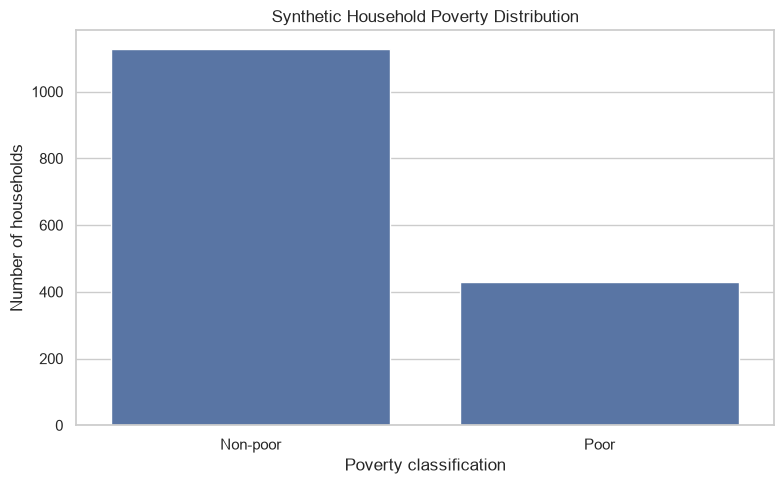

In [28]:
# Poverty distribution
plt.figure(figsize=(8, 5))

sns.countplot(
    data=survey,
    x="poverty_label"
)

plt.title("Synthetic Household Poverty Distribution")

plt.xlabel("Poverty classification")

plt.ylabel("Number of households")

plt.tight_layout()

plt.show()

#### 7. Aggregate survey outcomes to geographic zones

The household survey and MNO data will be joined at geographic-zone level.

Calculate:
- Number of surveyed households.
- Poverty rate.
- Average and median per-capita consumption.
- Share of households with electricity, improved water and sanitation.
- Average household size.

In [30]:
# AGGREGATE SURVEY OUTCOMES
survey_zone = (
    survey.groupby(
        "geographic_zone",
        observed=True
    )
    .agg(
        surveyed_households=("household_id", "nunique"),

        poverty_rate=("poverty_status", "mean"),

        mean_per_capita_consumption=(
            "monthly_per_capita_consumption",
            "mean"
        ),

        median_per_capita_consumption=(
            "monthly_per_capita_consumption",
            "median"
        ),

        mean_household_size=("household_size", "mean"),

        electricity_access_rate=("electricity_access", "mean"),

        improved_water_rate=("improved_water", "mean"),

        improved_sanitation_rate=("improved_sanitation", "mean"),

        mean_durable_assets=("durable_assets", "mean"),

        mean_education_years=("years_education", "mean")
    )
    .reset_index()
)


display(survey_zone.head())

print("Survey zones:", len(survey_zone))

,geographic_zone,surveyed_households,poverty_rate,mean_per_capita_consumption,median_per_capita_consumption,mean_household_size,electricity_access_rate,improved_water_rate,improved_sanitation_rate,mean_durable_assets,mean_education_years
0,-1.15_36.6,13,0.231,"4,340.011","4,827.343",3.923,0.615,0.538,0.615,1.769,7.769
1,-1.15_36.65,20,0.250,"4,734.587","3,981.405",4.350,0.850,0.900,0.750,2.500,5.700
2,-1.15_36.7,27,0.111,"5,697.559","5,136.250",4.333,0.556,0.778,0.556,2.000,8.000
3,-1.15_36.75,14,0.714,"3,061.318","2,618.549",4.786,0.500,0.643,0.571,2.429,8.071
4,-1.15_36.8,25,0.280,"5,324.955","4,678.687",4.240,0.680,0.720,0.600,2.040,8.360


Survey zones: 75


#### 8. Integrate MNO and survey datasets

In [ ]:
# JOIN MNO FEATURES AND SURVEY OUTCOMES
integrated_data = zone_features_public.merge(
    survey_zone,
    on="geographic_zone",
    how="inner",
    validate="one_to_one"
)


print("MNO zones:", len(zone_features_public))

print("Survey zones:", len(survey_zone))

print("Integrated zones:", len(integrated_data))

print(
    "Integrated households:",
    integrated_data["surveyed_households"].sum()
)


display(integrated_data.head())

MNO zones: 75
Survey zones: 75
Integrated zones: 75
Integrated households: 1557


,geographic_zone,latitude,longitude,unique_subscribers,total_events,unique_cells,active_days,nighttime_events,daytime_events,weekend_events,mean_events_per_subscriber,median_events_per_subscriber,mean_active_days_per_subscriber,nighttime_activity_ratio,daytime_activity_ratio,weekend_activity_ratio,events_per_cell,subscribers_per_cell,events_per_active_day,suppressed,surveyed_households,poverty_rate,mean_per_capita_consumption,median_per_capita_consumption,mean_household_size,electricity_access_rate,improved_water_rate,improved_sanitation_rate,mean_durable_assets,mean_education_years
0,-1.15_36.6,-1.121,36.629,547,1170,348,28,131,1039,463,2.139,1.000,1.501,0.112,0.888,0.396,3.362,1.572,41.786,False,13,0.231,"4,340.011","4,827.343",3.923,0.615,0.538,0.615,1.769,7.769
1,-1.15_36.65,-1.137,36.661,160,225,46,28,35,190,115,1.406,1.000,1.238,0.156,0.844,0.511,4.891,3.478,8.036,False,20,0.250,"4,734.587","3,981.405",4.350,0.850,0.900,0.750,2.500,5.700
2,-1.15_36.7,-1.113,36.732,165,201,92,28,16,185,111,1.218,1.000,1.079,0.080,0.920,0.552,2.185,1.793,7.179,False,27,0.111,"5,697.559","5,136.250",4.333,0.556,0.778,0.556,2.000,8.000
3,-1.15_36.75,-1.138,36.771,114,128,46,27,11,117,60,1.123,1.000,1.044,0.086,0.914,0.469,2.783,2.478,4.741,False,14,0.714,"3,061.318","2,618.549",4.786,0.500,0.643,0.571,2.429,8.071
4,-1.15_36.8,-1.129,36.818,65,70,29,21,6,64,47,1.077,1.000,1.015,0.086,0.914,0.671,2.414,2.241,3.333,False,25,0.280,"5,324.955","4,678.687",4.240,0.680,0.720,0.600,2.040,8.360


In [32]:
# Check for missing values
# INTEGRATION QUALITY CHECKS

integration_quality = pd.DataFrame({
    "column": integrated_data.columns,

    "missing_values": integrated_data.isna().sum().values,

    "missing_percentage": (
        integrated_data.isna().mean().values * 100
    )
})


display(
    integration_quality.sort_values(
        "missing_percentage",
        ascending=False
    )
)


assert integrated_data["geographic_zone"].is_unique

assert integrated_data["surveyed_households"].gt(0).all()

,column,missing_values,missing_percentage
0,geographic_zone,0,0.000
1,latitude,0,0.000
28,mean_durable_assets,0,0.000
27,improved_sanitation_rate,0,0.000
26,improved_water_rate,0,0.000
25,electricity_access_rate,0,0.000
24,mean_household_size,0,0.000
23,median_per_capita_consumption,0,0.000
22,mean_per_capita_consumption,0,0.000
21,poverty_rate,0,0.000


#### 9. Assess geographic coverage and representativeness
This section examines whether survey coverage and MNO activity are concentrated in a small number of geographic zones.

In [33]:
# GEOGRAPHIC COVERAGE
coverage_summary = pd.DataFrame({
    "metric": [
        "MNO geographic zones",
        "Survey geographic zones",
        "Integrated geographic zones",
        "Total surveyed households",
        "Median households per zone",
        "Minimum households per zone",
        "Maximum households per zone"
    ],

    "value": [
        zone_features_public["geographic_zone"].nunique(),

        survey_zone["geographic_zone"].nunique(),

        integrated_data["geographic_zone"].nunique(),

        integrated_data["surveyed_households"].sum(),

        integrated_data["surveyed_households"].median(),

        integrated_data["surveyed_households"].min(),

        integrated_data["surveyed_households"].max()
    ]
})


display(coverage_summary)

,metric,value
0,MNO geographic zones,75.000
1,Survey geographic zones,75.000
2,Integrated geographic zones,75.000
3,Total surveyed households,"1,557.000"
4,Median households per zone,20.000
5,Minimum households per zone,12.000
6,Maximum households per zone,30.000


#### 9.1 Survey coverage by zone

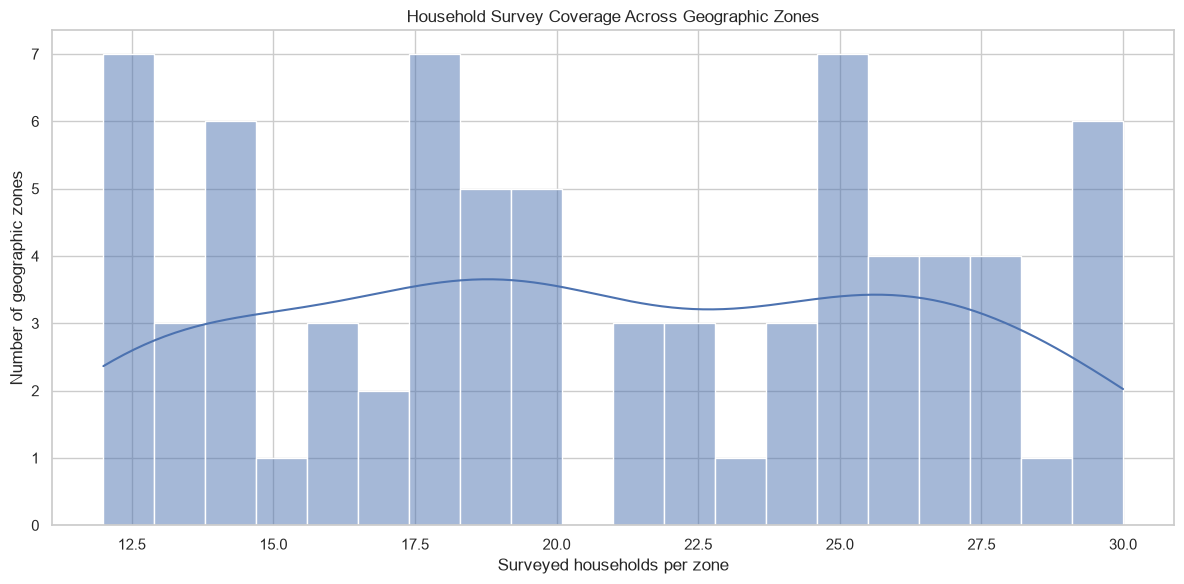

In [34]:
plt.figure(figsize=(12, 6))

sns.histplot(
    integrated_data["surveyed_households"],
    bins=20,
    kde=True
)

plt.title("Household Survey Coverage Across Geographic Zones")

plt.xlabel("Surveyed households per zone")

plt.ylabel("Number of geographic zones")

plt.tight_layout()

plt.show()

### Interpretation and Summary

The histogram shows the distribution of household survey coverage across geographic zones.

**Key findings:**

- **Survey coverage:** Each geographic zone has between 12 and 30 surveyed households.
- **Distribution:** Most zones have approximately 17–28 surveyed households.
- **Coverage consistency:** Household sampling is relatively well distributed, with no major concentration of survey coverage in just a few zones.
- **Variation:** Some zones have fewer households surveyed (12–16), while others have higher coverage (25–30).

**Key takeaway:**

The survey demonstrates reasonably balanced household coverage across geographic zones. This provides a useful foundation for comparing socioeconomic characteristics and household welfare across locations.

However, equal sampling per zone does not necessarily imply population representativeness. Population weights may be needed if zones differ significantly in household population.

#### 9.2 Compare MNO coverage and survey sample size

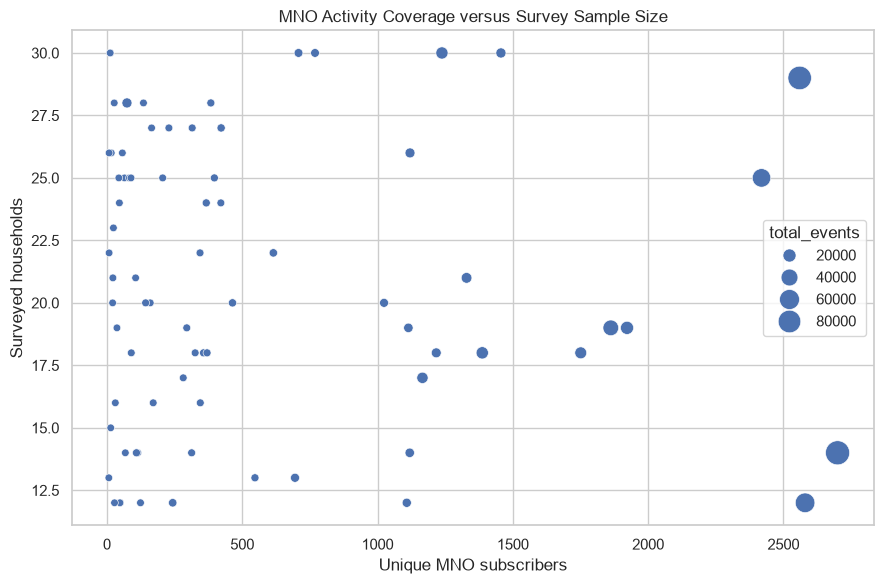

In [36]:
# MNO COVERAGE VS SURVEY SAMPLE SIZE
plot_data = integrated_data[
    [
        "unique_subscribers",
        "surveyed_households",
        "total_events"
    ]
].copy()


# Convert Pandas nullable numeric types to NumPy float.
for col in [
    "unique_subscribers",
    "surveyed_households",
    "total_events"
]:
    plot_data[col] = pd.to_numeric(
        plot_data[col],
        errors="coerce"
    ).astype(float)


plot_data = plot_data.dropna()


plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=plot_data,
    x="unique_subscribers",
    y="surveyed_households",
    size="total_events",
    sizes=(30, 300),
    legend="brief"
)

plt.title("MNO Activity Coverage versus Survey Sample Size")

plt.xlabel("Unique MNO subscribers")

plt.ylabel("Surveyed households")

plt.tight_layout()

plt.show()

### Interpretation and Summary

The scatter plot illustrates the relationship between MNO activity coverage and household survey sample sizes across geographic zones.

**Key findings:**

- **Uneven subscriber distribution:** Most geographic zones have relatively few unique MNO subscribers, while a small number have substantially higher subscriber counts (above 2,500).
- **Variation in survey coverage:** Survey sample sizes range from approximately 12 to 30 households per zone, regardless of MNO subscriber concentration.
- **High-activity zones:** Some zones with more than 2,500 unique subscribers also record relatively high MNO event volumes, indicating concentrated mobile network activity.
- **No clear relationship:** There is no obvious linear relationship between the number of surveyed households and unique MNO subscribers.
- **Activity concentration:** Bubble sizes indicate that a few geographic zones generate considerably more MNO events than others.

**Key takeaway:**

MNO activity is geographically concentrated, whereas household survey coverage is relatively evenly distributed across zones. This suggests that mobile network activity and survey sample size capture different aspects of geographic coverage.

For subsequent analysis, consider normalising MNO activity by subscriber counts and examining whether high-activity zones adequately represent the socioeconomic characteristics of their respective populations.

In [37]:
# Calculate the correlation
coverage_correlation = integrated_data[
    [
        "unique_subscribers",
        "total_events",
        "surveyed_households"
    ]
].corr(method="spearman")


display(coverage_correlation)

,unique_subscribers,total_events,surveyed_households
unique_subscribers,1.000,0.953,-0.044
total_events,0.953,1.000,-0.040
surveyed_households,-0.044,-0.040,1.000


### Interpretation and Summary

The Spearman correlation matrix reveals the following relationships between MNO activity and household survey coverage:

- **Unique subscribers vs. total events (0.953):** Very strong positive correlation. Geographic zones with more unique subscribers tend to generate substantially more MNO events.
- **Unique subscribers vs. surveyed households (-0.044):** Negligible negative correlation. The number of surveyed households is practically unrelated to MNO subscriber concentration.
- **Total events vs. surveyed households (-0.040):** Negligible negative correlation. Higher MNO activity does not correspond to larger household survey samples.

**Key takeaway:**

MNO activity is strongly associated with subscriber concentration, but neither subscriber numbers nor network activity has a meaningful relationship with household survey sample size.

This suggests that **mobile network activity and household survey coverage capture different dimensions of geographic representation**. Combining both datasets can therefore provide complementary insights for socioeconomic and population analysis.

*Note: Correlation indicates association, not causation.*

#### 9.3 Compare poverty rates across zones

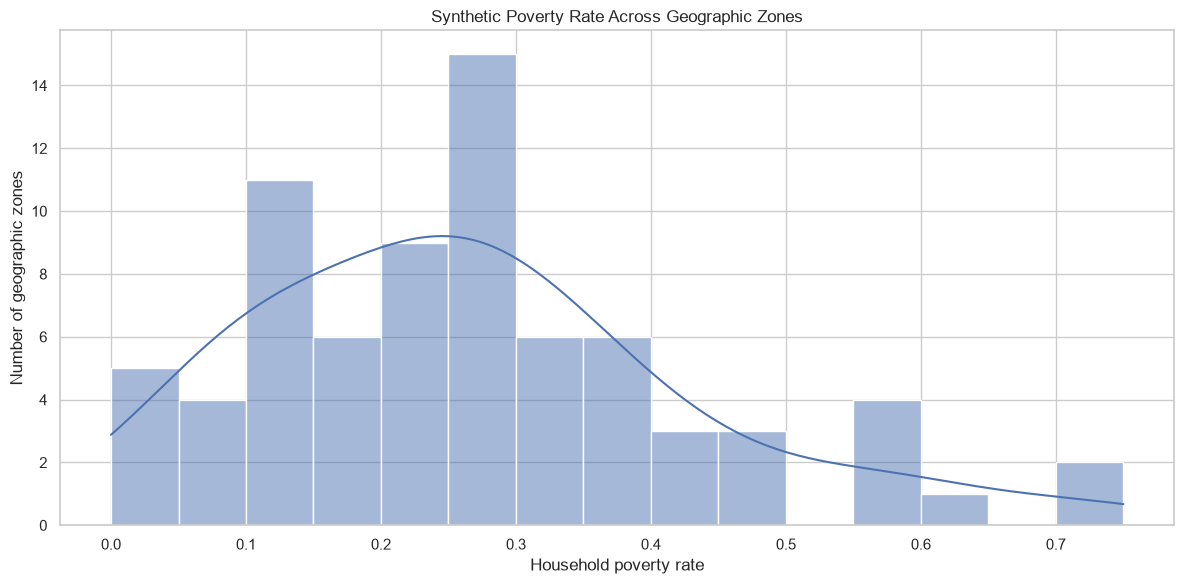

In [38]:
plt.figure(figsize=(12, 6))

sns.histplot(
    integrated_data["poverty_rate"],
    bins=15,
    kde=True
)

plt.title("Synthetic Poverty Rate Across Geographic Zones")

plt.xlabel("Household poverty rate")

plt.ylabel("Number of geographic zones")

plt.tight_layout()

plt.show()

### Interpretation and Summary

The histogram illustrates the distribution of synthetic household poverty rates across geographic zones.

**Key findings:**

- **Concentration:** Most geographic zones have poverty rates between 10% and 35%.
- **Peak distribution:** The highest concentration of zones falls around the 25–30% poverty rate.
- **Variation:** Poverty rates vary considerably across zones, ranging from approximately 0% to 75%.
- **Right-skewed distribution:** A smaller number of zones experience substantially higher poverty rates, particularly above 50%.
- **High-poverty zones:** A few geographic zones have poverty rates exceeding 60%, indicating greater socioeconomic vulnerability within the synthetic dataset.

**Key takeaway:**

The distribution suggests considerable variation in household poverty across geographic zones, with most zones experiencing moderate poverty rates and a smaller number exhibiting substantially higher poverty levels.

This provides a useful foundation for identifying potentially vulnerable geographic areas and examining whether MNO activity patterns correspond with differences in socioeconomic conditions.

*Note: These poverty estimates are derived from synthetic household data and should not be interpreted as actual poverty estimates for the study area.*

#### 10. Exploratory relationship between MNO features and poverty

Examine whether geographic MNO indicators are associated with the synthetic poverty outcomes.

These correlations are exploratory and should not be interpreted causally.

In [ ]:
# MNO-POVERTY CORRELATION
mno_feature_columns = [
    "unique_subscribers",
    "total_events",
    "unique_cells",
    "active_days",
    "nighttime_activity_ratio",
    "daytime_activity_ratio",
    "weekend_activity_ratio",
    "mean_events_per_subscriber",
    "median_events_per_subscriber",
    "mean_active_days_per_subscriber",
    "events_per_cell",
    "subscribers_per_cell",
    "events_per_active_day"
]


correlation_data = integrated_data[
    mno_feature_columns
    +
    [
        "poverty_rate",
        "mean_per_capita_consumption"
    ]
].corr(method="spearman")


display(
    correlation_data[
        [
            "poverty_rate",
            "mean_per_capita_consumption"
        ]
    ].sort_values(
        "poverty_rate",
        ascending=False
    )
)

,poverty_rate,mean_per_capita_consumption
poverty_rate,1.000,-0.845
events_per_active_day,0.108,-0.142
total_events,0.099,-0.138
daytime_activity_ratio,0.098,-0.028
events_per_cell,0.094,-0.096
active_days,0.082,-0.121
median_events_per_subscriber,0.070,-0.026
unique_subscribers,0.065,-0.106
mean_events_per_subscriber,0.056,-0.063
unique_cells,0.054,-0.096


### Interpretation and Summary

The Spearman correlation analysis examines the relationship between MNO activity indicators, household poverty rates and mean per-capita consumption.

**Key findings:**

- **Poverty and consumption (-0.845):** Strong negative correlation. Geographic zones with higher per-capita consumption tend to have substantially lower poverty rates.
- **Events per active day (0.108):** Weak positive correlation with poverty, suggesting slightly higher MNO activity intensity in zones with higher poverty rates.
- **Total events (0.099):** Weak positive relationship with poverty.
- **Daytime activity ratio (0.098):** Weak positive correlation with poverty.
- **Active days (0.082):** Weak positive association with poverty.
- **Unique subscribers (0.065):** Very weak positive relationship with poverty.
- **Weekend activity ratio (-0.109):** Weak negative correlation with poverty, suggesting slightly higher weekend activity in lower-poverty zones.

**Key takeaway:**

Most individual MNO activity indicators have very weak correlations with household poverty and consumption. This suggests that no single mobile network activity feature provides a strong standalone socioeconomic signal.

However, the strong negative relationship between poverty and per-capita consumption demonstrates that the synthetic socioeconomic indicators behave consistently with the expected relationship.

*Important: These findings are based on synthetic household survey data. They demonstrate analytical relationships within the simulated dataset, not validated relationships between actual MNO activity and poverty.*

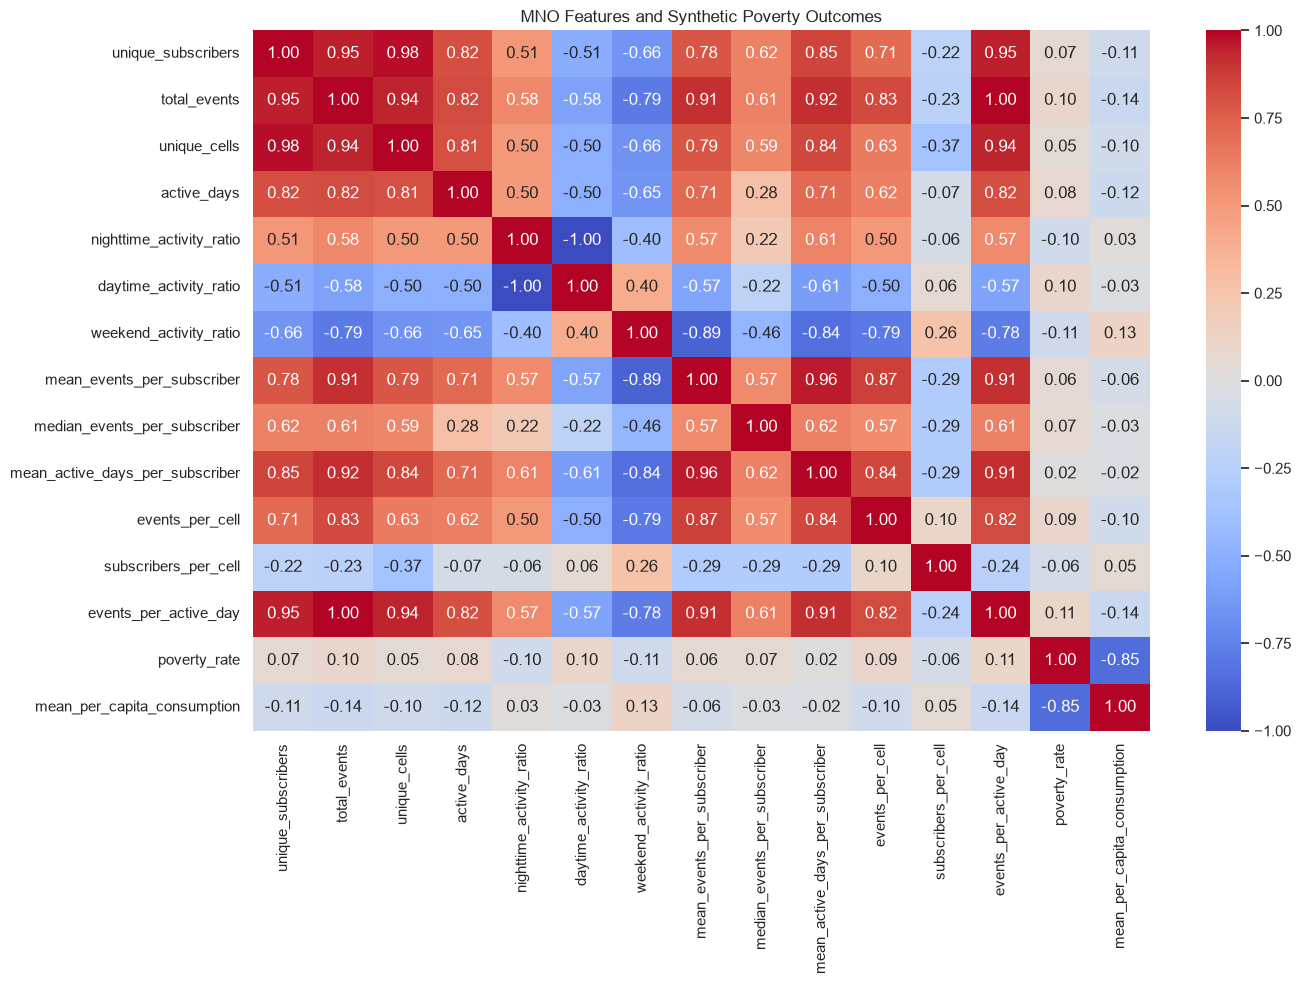

In [40]:
# Visualise the correlation matrix
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_data,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f"
)

plt.title("MNO Features and Synthetic Poverty Outcomes")

plt.tight_layout()

plt.show()

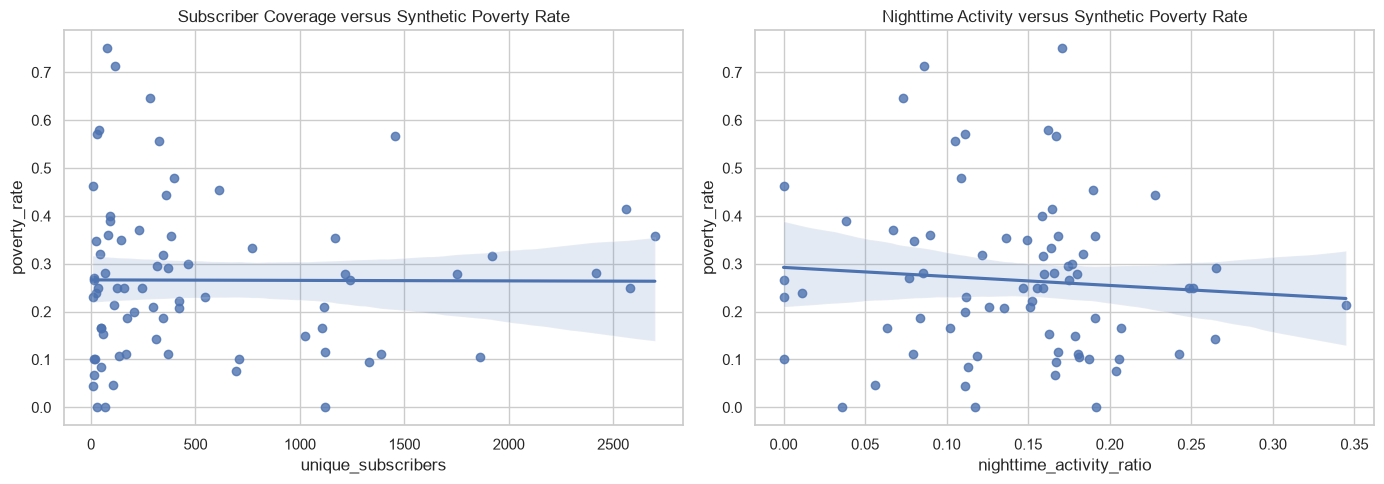

In [41]:
# Inspect selected relationships
fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)

sns.regplot(
    data=integrated_data,
    x="unique_subscribers",
    y="poverty_rate",
    ax=axes[0]
)

axes[0].set_title(
    "Subscriber Coverage versus Synthetic Poverty Rate"
)


sns.regplot(
    data=integrated_data,
    x="nighttime_activity_ratio",
    y="poverty_rate",
    ax=axes[1]
)

axes[1].set_title(
    "Nighttime Activity versus Synthetic Poverty Rate"
)


plt.tight_layout()

plt.show()

### Interpretation and Summary

The scatter plots examine the relationship between MNO subscriber coverage, nighttime activity and synthetic household poverty rates across geographic zones.

**Key findings:**

- **Unique subscribers vs. poverty:** The relationship is almost flat, indicating virtually no meaningful association between subscriber concentration and poverty rates.
- **Nighttime activity vs. poverty:** A slight negative relationship is observed, suggesting that zones with higher nighttime activity ratios tend to have marginally lower poverty rates.
- **Data dispersion:** Both plots show considerable variation in poverty rates across zones with similar MNO activity levels.
- **Predictive limitations:** Neither subscriber coverage nor nighttime activity appears sufficiently informative to explain geographic poverty differences independently.

**Key takeaway:**

The visualisations reinforce the correlation analysis: individual MNO indicators have limited standalone explanatory power for poverty estimation.

Combining multiple MNO features, such as subscriber activity, temporal behaviour, mobility patterns and geographic coverage, may provide more useful socioeconomic signals than relying on individual indicators.

*Note: These relationships are based on synthetic household survey data and should not be interpreted as evidence of actual relationships between mobile network activity and poverty.*

#### 11. Poverty classification model
We will predict whether a surveyed household is below the illustrative synthetic poverty threshold using only the aggregated MNO features associated with its geographic zone.

The household survey labels are used as outcomes. Household asset, education, water and sanitation fields are deliberately excluded from the predictors because they are survey variables, not MNO information.

We will also split training and testing by geographic zone. This prevents households from the same zone appearing in both sets.

In [42]:
# PREPARE HOUSEHOLD-LEVEL MODELLING DATA
from sklearn.dummy import DummyClassifier, DummyRegressor


# Attach zone-level MNO features to household records.
household_model_data = survey.merge(
    integrated_data[
        [
            "geographic_zone"
        ] + mno_feature_columns
    ],
    on="geographic_zone",
    how="inner",
    validate="many_to_one"
)


# Target variable.
TARGET_CLASS = "poverty_status"


# Only MNO-derived predictors.
MODEL_FEATURES = mno_feature_columns


model_data = household_model_data[
    [
        "household_id",
        "geographic_zone",
        TARGET_CLASS
    ] + MODEL_FEATURES
].copy()


print("Households available for modelling:", len(model_data))

print("Geographic zones:", model_data["geographic_zone"].nunique())

print(
    "Synthetic poverty prevalence:",
    model_data[TARGET_CLASS].mean()
)


display(model_data.head())

Households available for modelling: 1557
Geographic zones: 75
Synthetic poverty prevalence: 0.2761721258831085


,household_id,geographic_zone,poverty_status,unique_subscribers,total_events,unique_cells,active_days,nighttime_activity_ratio,daytime_activity_ratio,weekend_activity_ratio,mean_events_per_subscriber,median_events_per_subscriber,mean_active_days_per_subscriber,events_per_cell,subscribers_per_cell,events_per_active_day
0,SYN_000001,-1.15_36.6,0,547,1170,348,28,0.112,0.888,0.396,2.139,1.000,1.501,3.362,1.572,41.786
1,SYN_000002,-1.15_36.6,0,547,1170,348,28,0.112,0.888,0.396,2.139,1.000,1.501,3.362,1.572,41.786
2,SYN_000003,-1.15_36.6,0,547,1170,348,28,0.112,0.888,0.396,2.139,1.000,1.501,3.362,1.572,41.786
3,SYN_000004,-1.15_36.6,0,547,1170,348,28,0.112,0.888,0.396,2.139,1.000,1.501,3.362,1.572,41.786
4,SYN_000005,-1.15_36.6,0,547,1170,348,28,0.112,0.888,0.396,2.139,1.000,1.501,3.362,1.572,41.786


#### 11.1 Group-based train/test split

In [43]:
# GEOGRAPHICALLY GROUPED TRAIN/TEST SPLIT
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.25,
    random_state=RANDOM_STATE
)


train_idx, test_idx = next(
    splitter.split(
        model_data[MODEL_FEATURES],
        model_data[TARGET_CLASS],
        groups=model_data["geographic_zone"]
    )
)


X_train = model_data.iloc[train_idx][MODEL_FEATURES]

X_test = model_data.iloc[test_idx][MODEL_FEATURES]

y_train = model_data.iloc[train_idx][TARGET_CLASS]

y_test = model_data.iloc[test_idx][TARGET_CLASS]


train_zones = set(
    model_data.iloc[train_idx]["geographic_zone"]
)

test_zones = set(
    model_data.iloc[test_idx]["geographic_zone"]
)


assert train_zones.isdisjoint(test_zones)


print("Training households:", len(X_train))

print("Testing households:", len(X_test))

print("Training zones:", len(train_zones))

print("Testing zones:", len(test_zones))

print("Training poverty prevalence:", y_train.mean())

print("Testing poverty prevalence:", y_test.mean())

Training households: 1153
Testing households: 404
Training zones: 56
Testing zones: 19
Training poverty prevalence: 0.26019080659150046
Testing poverty prevalence: 0.3217821782178218


#### 11.2 Train a baseline and Random Forest model

In [44]:
# CLASSIFICATION PIPELINES
classification_preprocessor = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)


baseline_classifier = DummyClassifier(
    strategy="prior"
)


poverty_classifier = Pipeline(
    steps=[
        (
            "preprocessor",
            classification_preprocessor
        ),
        (
            "model",
            RandomForestClassifier(
                n_estimators=300,
                max_depth=5,
                min_samples_leaf=5,
                class_weight="balanced",
                random_state=RANDOM_STATE,
                n_jobs=-1
            )
        )
    ]
)


# Baseline
baseline_classifier.fit(
    X_train,
    y_train
)


baseline_predictions = baseline_classifier.predict(
    X_test
)


# Random Forest
poverty_classifier.fit(
    X_train,
    y_train
)


poverty_predictions = poverty_classifier.predict(
    X_test
)


poverty_probabilities = poverty_classifier.predict_proba(
    X_test
)[:, 1]

#### 11.3 Evaluate classification performance

In [45]:
# CLASSIFICATION METRICS

classification_results = []


def evaluate_classifier(
    name,
    y_true,
    predictions,
    probabilities
):

    return {
        "model": name,

        "precision": precision_score(
            y_true,
            predictions,
            zero_division=0
        ),

        "recall": recall_score(
            y_true,
            predictions,
            zero_division=0
        ),

        "f1_score": f1_score(
            y_true,
            predictions,
            zero_division=0
        ),

        "roc_auc": (
            roc_auc_score(y_true, probabilities)
            if len(np.unique(y_true)) == 2
            else np.nan
        ),

        "average_precision": (
            average_precision_score(y_true, probabilities)
            if len(np.unique(y_true)) == 2
            else np.nan
        )
    }


classification_results.append(
    evaluate_classifier(
        "Baseline",
        y_test,
        baseline_predictions,
        baseline_classifier.predict_proba(X_test)[:, 1]
    )
)


classification_results.append(
    evaluate_classifier(
        "Random Forest",
        y_test,
        poverty_predictions,
        poverty_probabilities
    )
)


classification_metrics = pd.DataFrame(
    classification_results
)


display(classification_metrics)

,model,precision,recall,f1_score,roc_auc,average_precision
0,Baseline,0.000,0.000,0.000,0.500,0.322
1,Random Forest,0.310,0.300,0.305,0.500,0.325


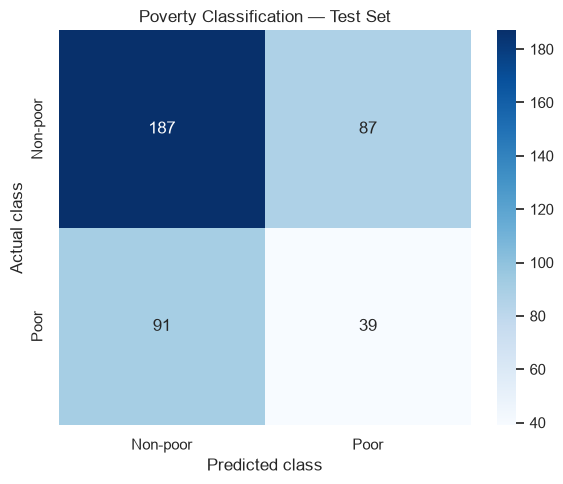

In [46]:
# Confusion matrix

cm = confusion_matrix(
    y_test,
    poverty_predictions,
    labels=[0, 1]
)


plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non-poor", "Poor"],
    yticklabels=["Non-poor", "Poor"]
)

plt.title("Poverty Classification — Test Set")

plt.xlabel("Predicted class")

plt.ylabel("Actual class")

plt.tight_layout()

plt.show()

In [47]:
print(
    classification_report(
        y_test,
        poverty_predictions,
        target_names=[
            "Non-poor",
            "Poor"
        ],
        zero_division=0
    )
)

              precision    recall  f1-score   support

    Non-poor       0.67      0.68      0.68       274
        Poor       0.31      0.30      0.30       130

    accuracy                           0.56       404
   macro avg       0.49      0.49      0.49       404
weighted avg       0.56      0.56      0.56       404



### Interpretation and Summary

The Random Forest model performs only marginally better than the baseline when predicting household poverty status. However, its overall predictive performance remains weak.

**Key findings:**

- **Accuracy (56%):** The model correctly classifies only 56% of households, indicating limited predictive capability.
- **Precision (31%):** Only 31% of households classified as poor are actually poor.
- **Recall (30%):** The model identifies only 30% of genuinely poor households, missing approximately 70%.
- **F1-score (0.305):** Indicates poor balance between precision and recall.
- **ROC-AUC (0.500):** The model performs no better than random guessing in distinguishing poor from non-poor households.
- **Average Precision (0.325):** Only marginally better than the baseline prevalence of approximately 32.2%.

**Confusion matrix interpretation:**

- 187 non-poor households correctly classified.
- 87 non-poor households incorrectly classified as poor.
- 39 poor households correctly identified.
- 91 poor households incorrectly classified as non-poor.

**Key takeaway:**

The Random Forest model does not currently provide reliable poverty classification. In particular, its low recall means it misses most genuinely poor households.

The results suggest that the available MNO activity features do not contain sufficient predictive information to reliably distinguish poor from non-poor households in this experiment.

**Recommended next steps:**

1. Engineer additional features capturing subscriber mobility, activity regularity and geographic concentration.
2. Investigate relationships between MNO activity and household consumption.
3. Test alternative models such as XGBoost, LightGBM and Logistic Regression.
4. Address class imbalance and experiment with decision thresholds.
5. Validate using real household survey data before drawing conclusions about poverty prediction.

*Important: The household survey is synthetic, so these results demonstrate the limitations of the current experimental setup rather than the real-world predictive potential of MNO data.*

#### 12. Poverty expenditure regression

We will also investigate whether MNO features can estimate geographic differences in household per-capita consumption.

This is a regression task rather than a poverty classification task.

The outcome remains synthetic and should not be interpreted as actual household expenditure.

In [48]:
# REGRESSION TARGET
TARGET_REGRESSION = "monthly_per_capita_consumption"


regression_data = household_model_data[
    [
        "household_id",
        "geographic_zone",
        TARGET_REGRESSION
    ] + MODEL_FEATURES
].copy()


# Use the same geographic split.
regression_train = regression_data.iloc[train_idx].copy()

regression_test = regression_data.iloc[test_idx].copy()


X_reg_train = regression_train[MODEL_FEATURES]

X_reg_test = regression_test[MODEL_FEATURES]

y_reg_train = regression_train[TARGET_REGRESSION]

y_reg_test = regression_test[TARGET_REGRESSION]


assert set(
    regression_train["geographic_zone"]
).isdisjoint(
    set(regression_test["geographic_zone"])
)

#### 12.1 Train baseline and Random Forest regression models

In [49]:
# REGRESSION MODELS

baseline_regressor = DummyRegressor(
    strategy="median"
)


poverty_regressor = Pipeline(
    steps=[
        (
            "preprocessor",
            Pipeline(
                steps=[
                    (
                        "imputer",
                        SimpleImputer(strategy="median")
                    ),
                    (
                        "scaler",
                        StandardScaler()
                    )
                ]
            )
        ),
        (
            "model",
            RandomForestRegressor(
                n_estimators=300,
                max_depth=5,
                min_samples_leaf=5,
                random_state=RANDOM_STATE,
                n_jobs=-1
            )
        )
    ]
)


baseline_regressor.fit(
    X_reg_train,
    y_reg_train
)


poverty_regressor.fit(
    X_reg_train,
    y_reg_train
)


baseline_reg_predictions = baseline_regressor.predict(
    X_reg_test
)


reg_predictions = poverty_regressor.predict(
    X_reg_test
)

#### 12.2 Evaluate regression performance

In [50]:
# REGRESSION METRICS

def regression_metrics(
    name,
    actual,
    predicted
):

    return {
        "model": name,

        "MAE": mean_absolute_error(
            actual,
            predicted
        ),

        "RMSE": np.sqrt(
            mean_squared_error(
                actual,
                predicted
            )
        ),

        "R2": r2_score(
            actual,
            predicted
        )
    }


regression_results = pd.DataFrame([
    regression_metrics(
        "Baseline",
        y_reg_test,
        baseline_reg_predictions
    ),

    regression_metrics(
        "Random Forest",
        y_reg_test,
        reg_predictions
    )
])


display(regression_results)

,model,MAE,RMSE,R2
0,Baseline,"2,039.792","2,953.335",-0.003
1,Random Forest,"2,446.811","3,249.310",-0.214


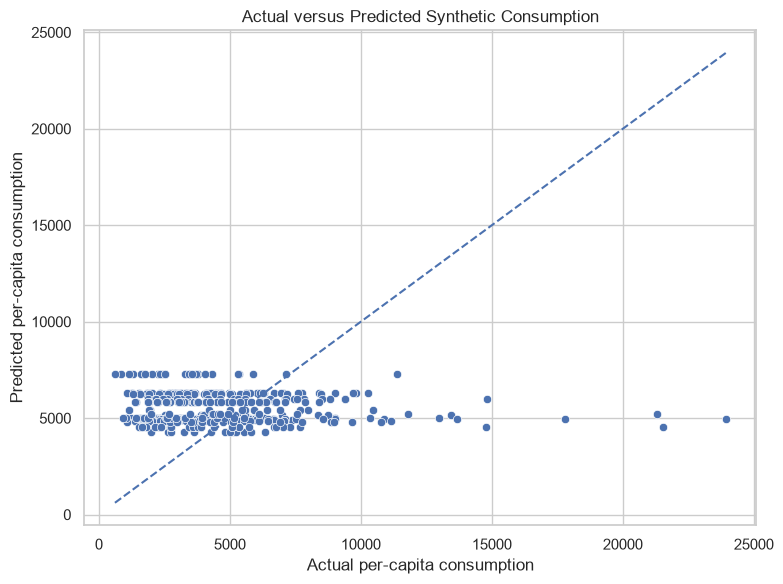

In [51]:
# Actual versus predicted consumption

plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=y_reg_test,
    y=reg_predictions
)

min_value = min(
    y_reg_test.min(),
    reg_predictions.min()
)

max_value = max(
    y_reg_test.max(),
    reg_predictions.max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.title("Actual versus Predicted Synthetic Consumption")

plt.xlabel("Actual per-capita consumption")

plt.ylabel("Predicted per-capita consumption")

plt.tight_layout()

plt.show()

### Interpretation and Summary

The Random Forest regression model performs worse than the baseline model in predicting household per-capita consumption. It struggles to capture the variation in actual household consumption.

**Key findings:**

- **MAE (2,446.81):** The model's predictions deviate from actual consumption by approximately 2,447 units on average.
- **RMSE (3,249.31):** The relatively high error indicates substantial prediction errors, particularly for households with unusually high consumption.
- **R² (-0.214):** The model explains none of the variation in consumption and performs worse than simply predicting the average consumption for every household.
- **Baseline comparison:** The baseline performs better, with a lower MAE (2,039.79), lower RMSE (2,953.34), and R² closer to zero (-0.003).

**Scatterplot interpretation:**

- Predictions are heavily concentrated between approximately 4,500 and 7,000 units.
- The model struggles to predict households with very high consumption.
- Predictions do not closely follow the diagonal reference line, indicating poor agreement between actual and predicted values.
- The model appears to regress towards the average, failing to capture differences between households.

**Key takeaway:**

The Random Forest model does not provide reliable household consumption estimates. The available MNO features currently have limited predictive value for explaining household consumption differences in this experiment.

**Recommended next steps:**

1. Engineer richer MNO features, particularly mobility, subscriber activity patterns and geographic concentration.
2. Investigate nonlinear relationships between MNO activity and household consumption.
3. Experiment with XGBoost, LightGBM and CatBoost.
4. Investigate outliers and consumption distribution before modelling.
5. Validate using real household survey data rather than synthetic consumption data.

*Important: Since the household consumption data is synthetically generated, these results should be interpreted as an assessment of the current experimental pipeline, not evidence that MNO data cannot predict real-world household consumption.*

#### 13. Feature importance
We will use permutation importance on the geographically held-out test data.

In [52]:
# PERMUTATION IMPORTANCE
classification_importance = permutation_importance(
    poverty_classifier,
    X_test,
    y_test,
    n_repeats=20,
    random_state=RANDOM_STATE,
    scoring="average_precision"
)


classification_importance_df = pd.DataFrame({
    "feature": MODEL_FEATURES,

    "importance_mean": (
        classification_importance.importances_mean
    ),

    "importance_std": (
        classification_importance.importances_std
    )
}).sort_values(
    "importance_mean",
    ascending=False
)


display(classification_importance_df)

,feature,importance_mean,importance_std
7,mean_events_per_subscriber,0.008,0.006
4,nighttime_activity_ratio,0.003,0.009
8,median_events_per_subscriber,0.001,0.003
11,subscribers_per_cell,0.001,0.011
2,unique_cells,-0.002,0.009
3,active_days,-0.002,0.007
1,total_events,-0.003,0.009
5,daytime_activity_ratio,-0.004,0.011
0,unique_subscribers,-0.005,0.010
9,mean_active_days_per_subscriber,-0.005,0.012


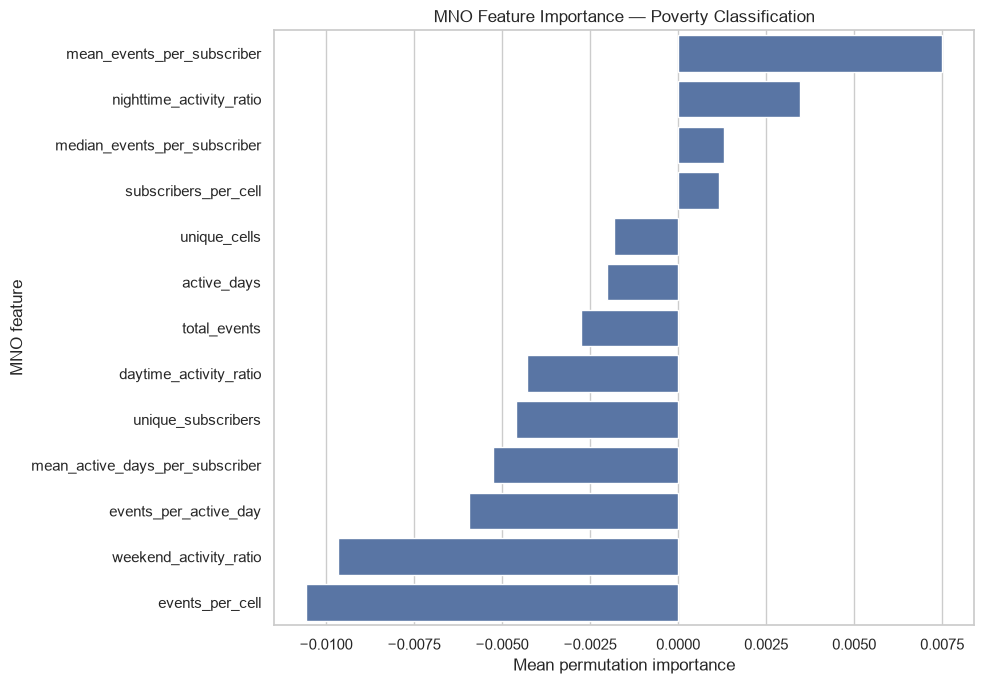

In [53]:
plt.figure(figsize=(10, 7))

sns.barplot(
    data=classification_importance_df,
    x="importance_mean",
    y="feature"
)

plt.title("MNO Feature Importance — Poverty Classification")

plt.xlabel("Mean permutation importance")

plt.ylabel("MNO feature")

plt.tight_layout()

plt.show()

#### 14. Assess geographic bias and uncertainty
A poverty estimate based on MNO data can be misleading if some locations have better network coverage, more active subscribers or larger survey samples than others.

Examine the relationship between MNO coverage and model errors.

In [54]:
# TEST-SET PREDICTIONS BY GEOGRAPHIC ZONE

test_predictions = regression_test[
    [
        "household_id",
        "geographic_zone",
        TARGET_REGRESSION
    ]
].copy()


test_predictions["predicted_consumption"] = (
    reg_predictions
)


test_predictions["absolute_error"] = (
    test_predictions[TARGET_REGRESSION]
    - test_predictions["predicted_consumption"]
).abs()


test_zone_errors = (
    test_predictions.groupby("geographic_zone")
    .agg(
        households=("household_id", "nunique"),

        mean_actual_consumption=(
            TARGET_REGRESSION,
            "mean"
        ),

        mean_predicted_consumption=(
            "predicted_consumption",
            "mean"
        ),

        mean_absolute_error=(
            "absolute_error",
            "mean"
        )
    )
    .reset_index()
)


test_zone_errors = test_zone_errors.merge(
    integrated_data[
        [
            "geographic_zone",
            "unique_subscribers",
            "total_events",
            "unique_cells"
        ]
    ],
    on="geographic_zone",
    how="left",
    validate="one_to_one"
)


display(
    test_zone_errors.sort_values(
        "mean_absolute_error",
        ascending=False
    )
)

,geographic_zone,households,mean_actual_consumption,mean_predicted_consumption,mean_absolute_error,unique_subscribers,total_events,unique_cells
3,-1.15_37.05,28,"3,272.698","7,283.523","4,303.934",27,27,15
10,-1.35_36.8,25,"5,837.959","4,948.949","3,196.074",2419,50260,1924
17,-1.4_36.9,12,"6,476.867","5,209.532","3,053.994",1108,4624,646
2,-1.15_36.85,25,"3,796.721","6,328.498","2,749.471",44,49,21
6,-1.25_37.0,26,"5,587.760","5,992.364","2,604.637",16,26,6
4,-1.25_36.6,25,"3,948.320","6,276.848","2,578.080",83,100,41
5,-1.25_36.7,25,"4,061.596","5,002.316","2,523.653",397,993,83
14,-1.45_36.95,30,"5,010.162","4,524.896","2,449.579",769,3203,431
1,-1.15_36.8,25,"5,324.955","6,277.388","2,367.189",65,70,29
15,-1.4_36.75,16,"5,577.911","4,798.199","2,284.317",345,586,118


### Interpretation and Summary

The results show substantial variation in prediction accuracy across geographic zones. The Random Forest model performs better in some zones than others, suggesting that its ability to estimate household consumption is inconsistent geographically.

**Key findings:**

- **Highest prediction errors:** Zone `-1.15_37.05` has the highest MAE (4,303.93), followed by `-1.35_36.8` (3,196.07) and `-1.4_36.9` (3,053.99).
- **Lowest prediction error:** Zone `-1.15_36.6` has the lowest MAE (1,159.84), indicating relatively better predictions.
- **High-activity zones:** Zones `-1.35_36.8` and `-1.35_36.85` have substantial MNO activity (2,419 and 2,560 subscribers respectively), but still experience considerable prediction errors.
- **Low-activity zones:** Some zones with very few subscribers also have large prediction errors, suggesting that limited MNO coverage may affect prediction reliability.
- **Prediction bias:** The model sometimes overestimates consumption in lower-consumption zones and underestimates it in higher-consumption zones.

**Key takeaway:**

Prediction accuracy varies considerably across geographic zones. Higher MNO subscriber coverage does not automatically translate into better household consumption predictions.

**Recommended next steps:**

1. Investigate geographic zones with the largest prediction errors.
2. Examine whether MNO coverage and activity patterns explain differences in prediction accuracy.
3. Engineer additional geographic and mobility features.
4. Consider zone-level model calibration or separate models for sufficiently populated zones.

*Important: These findings are based on synthetic household consumption data and should be treated as exploratory rather than evidence of real-world predictive performance.*

#### 14.1 Examine error against MNO coverage

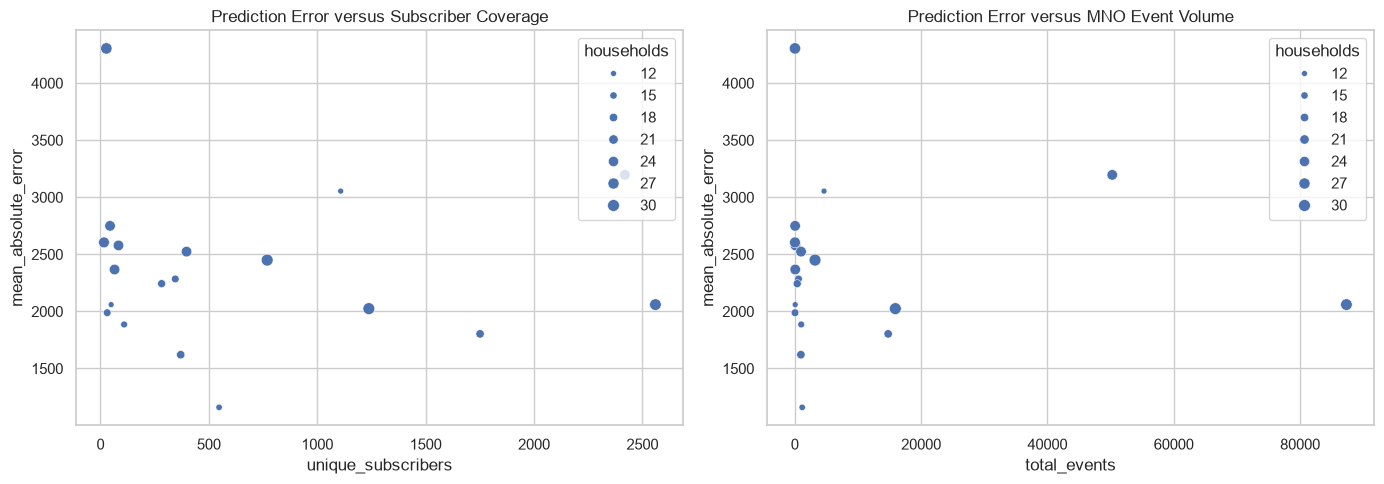

In [55]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)


sns.scatterplot(
    data=test_zone_errors,
    x="unique_subscribers",
    y="mean_absolute_error",
    size="households",
    ax=axes[0]
)

axes[0].set_title(
    "Prediction Error versus Subscriber Coverage"
)


sns.scatterplot(
    data=test_zone_errors,
    x="total_events",
    y="mean_absolute_error",
    size="households",
    ax=axes[1]
)

axes[1].set_title(
    "Prediction Error versus MNO Event Volume"
)


plt.tight_layout()

plt.show()

### Interpretation and Summary

The scatterplots show that prediction errors vary considerably across geographic zones, with no clear relationship between MNO subscriber coverage, event volume and model accuracy.

**Key findings:**

- **Subscriber coverage:** Zones with more subscribers do not consistently have lower prediction errors. Some highly covered zones still experience MAEs above 2,000.
- **MNO event volume:** Higher event volumes do not necessarily improve prediction accuracy. For example, a zone with approximately 50,000 events has an MAE above 3,000.
- **Low-activity zones:** Several zones with very few subscribers also exhibit high prediction errors, suggesting that sparse MNO activity may limit the information available for prediction.
- **Outliers:** The highest prediction error is approximately 4,304, occurring in a zone with very low subscriber coverage.
- **Household sample size:** Differences in the number of surveyed households do not reveal an obvious relationship with prediction errors.

**Key takeaway:**

MNO subscriber coverage and event volume alone are insufficient to explain geographic differences in household consumption prediction accuracy. More informative features capturing subscriber behaviour, mobility patterns and socioeconomic characteristics may be needed.

**Recommended next step:** Investigate whether combining MNO activity features with geographic mobility indicators improves prediction accuracy across different zones.

*Note: These findings are exploratory because the household consumption targets are synthetically generated.*

#### 14.2 Compare high- and low-coverage zones

In [ ]:
# COVERAGE STRATIFICATION

test_zone_errors["coverage_group"] = pd.qcut(
    test_zone_errors["unique_subscribers"],
    q=min(3, test_zone_errors["unique_subscribers"].nunique()),
    labels=False,
    duplicates="drop"
)


coverage_error_summary = (
    test_zone_errors.groupby(
        "coverage_group",
        observed=True
    )
    .agg(
        zones=("geographic_zone", "nunique"),

        mean_subscribers=("unique_subscribers", "mean"),

        mean_absolute_error=("mean_absolute_error", "mean"),

        median_absolute_error=("mean_absolute_error", "median")
    )
    .reset_index()
)


display(coverage_error_summary)

,coverage_group,zones,mean_subscribers,mean_absolute_error,median_absolute_error
0,0,7,45.000,"2,664.493","2,578.080"
1,1,6,341.667,"1,952.924","2,064.512"
2,2,6,"1,640.833","2,431.127","2,254.623"


### Interpretation and Summary

The results suggest that MNO subscriber coverage has some relationship with prediction accuracy, but the relationship is not linear.

**Key findings:**

- **Low coverage (Group 0):** Zones averaging 45 subscribers have the highest mean prediction error (2,664.49).
- **Moderate coverage (Group 1):** Zones averaging 342 subscribers have the lowest mean prediction error (1,952.92), suggesting better prediction performance.
- **High coverage (Group 2):** Despite averaging approximately 1,641 subscribers, these zones have a higher mean prediction error (2,431.13) than the moderate-coverage group.

**Key takeaway:**

Moderate MNO coverage appears to provide better prediction accuracy than either very low or very high coverage. However, increasing subscriber coverage does not automatically improve model performance.

This suggests that the quality and representativeness of MNO activity features may matter more than subscriber volume alone.

*Note: These are exploratory findings based on synthetic household consumption data and should not be interpreted as evidence of a real-world relationship.*

#### 14.3 Poverty-rate uncertainty by geographic zone

In [57]:
# ZONE-LEVEL POVERTY RATE UNCERTAINTY

survey_uncertainty = survey_zone.copy()


survey_uncertainty["poverty_standard_error"] = np.sqrt(
    (
        survey_uncertainty["poverty_rate"]
        *
        (1 - survey_uncertainty["poverty_rate"])
    )
    /
    survey_uncertainty["surveyed_households"]
)


survey_uncertainty["poverty_ci_lower"] = (
    survey_uncertainty["poverty_rate"]
    - 1.96 * survey_uncertainty["poverty_standard_error"]
).clip(0, 1)


survey_uncertainty["poverty_ci_upper"] = (
    survey_uncertainty["poverty_rate"]
    + 1.96 * survey_uncertainty["poverty_standard_error"]
).clip(0, 1)


display(
    survey_uncertainty[
        [
            "geographic_zone",
            "surveyed_households",
            "poverty_rate",
            "poverty_ci_lower",
            "poverty_ci_upper"
        ]
    ].head(20)
)

,geographic_zone,surveyed_households,poverty_rate,poverty_ci_lower,poverty_ci_upper
0,-1.15_36.6,13,0.231,0.002,0.460
1,-1.15_36.65,20,0.250,0.060,0.440
2,-1.15_36.7,27,0.111,0.000,0.230
3,-1.15_36.75,14,0.714,0.478,0.951
4,-1.15_36.8,25,0.280,0.104,0.456
5,-1.15_36.85,25,0.320,0.137,0.503
6,-1.15_36.9,27,0.370,0.188,0.553
7,-1.15_36.95,22,0.455,0.246,0.663
8,-1.15_37.0,27,0.296,0.124,0.469
9,-1.15_37.05,28,0.571,0.388,0.755


#### 15. Compare random and geographic train/test splits

In [58]:
# RANDOM HOUSEHOLD SPLIT

X_random_train, X_random_test, y_random_train, y_random_test = (
    train_test_split(
        model_data[MODEL_FEATURES],
        model_data[TARGET_CLASS],
        test_size=0.25,
        random_state=RANDOM_STATE,
        stratify=model_data[TARGET_CLASS]
    )
)


random_split_model = Pipeline(
    steps=[
        (
            "preprocessor",
            Pipeline(
                steps=[
                    (
                        "imputer",
                        SimpleImputer(strategy="median")
                    ),
                    (
                        "scaler",
                        StandardScaler()
                    )
                ]
            )
        ),
        (
            "model",
            RandomForestClassifier(
                n_estimators=300,
                max_depth=5,
                min_samples_leaf=5,
                class_weight="balanced",
                random_state=RANDOM_STATE,
                n_jobs=-1
            )
        )
    ]
)


random_split_model.fit(
    X_random_train,
    y_random_train
)


random_split_predictions = random_split_model.predict(
    X_random_test
)


random_split_probabilities = (
    random_split_model.predict_proba(X_random_test)[:, 1]
)


random_split_metrics = evaluate_classifier(
    "Random household split",
    y_random_test,
    random_split_predictions,
    random_split_probabilities
)


geographic_split_metrics = evaluate_classifier(
    "Geographic zone holdout",
    y_test,
    poverty_predictions,
    poverty_probabilities
)


split_comparison = pd.DataFrame([
    random_split_metrics,
    geographic_split_metrics
])


display(split_comparison)

,model,precision,recall,f1_score,roc_auc,average_precision
0,Random household split,0.347,0.611,0.443,0.617,0.396
1,Geographic zone holdout,0.310,0.300,0.305,0.500,0.325


### Interpretation and Summary

The results show that model performance drops significantly when evaluated using a geographic zone holdout rather than a random household split.

**Key findings:**

- **Random household split:** Achieves an F1-score of 0.443, recall of 61.1%, and ROC-AUC of 0.617. The model demonstrates some ability to identify poor households when training and testing on randomly selected households.
- **Geographic zone holdout:** Performance drops to an F1-score of 0.305, recall of 30%, and ROC-AUC of 0.500. This indicates that the model struggles to identify poor households in previously unseen geographic zones.
- **Recall:** Falls from 61.1% to 30%, meaning the model misses significantly more poor households under geographic validation.
- **ROC-AUC:** Drops to 0.500, indicating no meaningful ability to distinguish between poor and non-poor households in unseen zones.

**Key takeaway:**

The random household split likely overestimates the model's ability to generalise geographically. The geographic holdout provides a more realistic assessment of performance when deploying the model in new locations.

The results suggest that the current MNO features do not adequately capture the socioeconomic differences needed to identify poor households across unseen geographic zones.

*Important: These results are based on synthetic household survey data. They demonstrate a validation challenge within the experiment, not proven real-world predictive capability.*

#### 16. Methodological limitations and safeguards

#### 1. Synthetic Data

The MNO records and household survey are synthetic.

The poverty labels do not represent verified Kenyan household poverty
status. Model results cannot be interpreted as evidence of real-world
poverty prediction.

#### 2. Ecological Fallacy

The MNO features are aggregated at geographic-zone level, while poverty
is measured at household level.

A geographic association does not establish that an individual
subscriber or household is poor.

The model should not be used to classify individual subscribers.

#### 3. Survey Representativeness

The synthetic survey has no real sampling weights, non-response
adjustments or official sampling design.

A real implementation must assess whether surveyed households
represent the population in each geographic area.

#### 4. MNO Coverage Bias

Subscriber activity is not equivalent to population density.

MNO coverage, handset ownership, network access, SIM ownership,
subscriber behaviour and operator market share may all affect
the observed data.

#### 5. Temporal Misalignment

MNO activity and household consumption surveys must refer to
compatible periods.

Economic shocks, seasonal employment, displacement and price
changes may make historical survey labels unsuitable for current
poverty estimation.

#### 6. Privacy

MNO features are aggregated geographically.

Subscriber identifiers are not linked to household survey records.

Small geographic groups should be suppressed or aggregated further.

#### 7. Model Generalisation

Random household splits can produce optimistic results because
households in the same geographic zone share identical MNO features.

Geographic holdout evaluation is therefore preferred.

#### 8. Humanitarian Use

MNO-derived estimates should complement, not replace, representative
household surveys and official poverty statistics.

They should not be used alone to determine individual eligibility
for cash transfers or humanitarian assistance.

#### 17. Export Notebook 06 outputs

In [60]:
# EXPORT NOTEBOOK 06 OUTPUTS
# 1. MNO geographic features — private analytical output
zone_features.to_csv(
    NOTEBOOK06_OUTPUT / "mno_geographic_features_private.csv",
    index=False
)


# 2. Synthetic household survey — private
survey.to_csv(
    NOTEBOOK06_OUTPUT / "synthetic_household_survey_private.csv",
    index=False
)


# 3. Aggregated survey outcomes
survey_zone.to_csv(
    NOTEBOOK06_OUTPUT / "survey_zone_aggregates.csv",
    index=False
)


# 4. Integrated MNO and survey data
integrated_data.to_csv(
    NOTEBOOK06_OUTPUT / "integrated_zone_data_private.csv",
    index=False
)


# 5. Geographic coverage summary
coverage_summary.to_csv(
    NOTEBOOK06_OUTPUT / "survey_coverage_summary.csv",
    index=False
)


# 6. Correlation analysis
correlation_data.to_csv(
    NOTEBOOK06_OUTPUT / "mno_poverty_correlations.csv"
)


# 7. Classification metrics
classification_metrics.to_csv(
    NOTEBOOK06_OUTPUT / "poverty_classification_metrics.csv",
    index=False
)


# 8. Regression metrics
regression_results.to_csv(
    NOTEBOOK06_OUTPUT / "poverty_regression_metrics.csv",
    index=False
)


# 9. Classification feature importance
classification_importance_df.to_csv(
    NOTEBOOK06_OUTPUT / "poverty_feature_importance.csv",
    index=False
)


# 10. Geographic prediction errors
test_zone_errors.to_csv(
    NOTEBOOK06_OUTPUT / "geographic_prediction_errors_private.csv",
    index=False
)


# 11. Coverage error comparison
coverage_error_summary.to_csv(
    NOTEBOOK06_OUTPUT / "coverage_error_summary.csv",
    index=False
)


# 12. Survey uncertainty
survey_uncertainty.to_csv(
    NOTEBOOK06_OUTPUT / "survey_poverty_uncertainty.csv",
    index=False
)


# 13. Train/test split comparison
split_comparison.to_csv(
    NOTEBOOK06_OUTPUT / "split_strategy_comparison.csv",
    index=False
)


print("Notebook 06 exports completed.")

print("Output directory:", NOTEBOOK06_OUTPUT)

for file in sorted(NOTEBOOK06_OUTPUT.glob("*.csv")):
    print(
        file.name,
        f"{file.stat().st_size:,} bytes"
    )

Notebook 06 exports completed.
Output directory: /Users/Apple/Documents/mno_mobility_intelligence_residence_and_population_displacement_inference/data/processed/notebook_06
coverage_error_summary.csv 245 bytes
geographic_prediction_errors_private.csv 1,729 bytes
integrated_zone_data_private.csv 25,715 bytes
mno_geographic_features_private.csv 15,318 bytes
mno_poverty_correlations.csv 4,803 bytes
poverty_classification_metrics.csv 189 bytes
poverty_feature_importance.csv 872 bytes
poverty_regression_metrics.csv 158 bytes
split_strategy_comparison.csv 273 bytes
survey.csv 114,058 bytes
survey_coverage_summary.csv 232 bytes
survey_poverty_uncertainty.csv 15,302 bytes
survey_zone_aggregates.csv 11,446 bytes
synthetic_household_survey_private.csv 157,307 bytes


#### 18. Final quality checks

In [61]:
# NOTEBOOK 06 QUALITY CHECKS

# Geographic zones must be unique in the integrated dataset.
assert integrated_data["geographic_zone"].is_unique


# Poverty rates must be between 0 and 1.
assert survey_zone["poverty_rate"].between(0, 1).all()


# Poverty classifications must be binary.
assert set(survey["poverty_status"].unique()).issubset({0, 1})


# No negative consumption values.
assert (
    survey["monthly_per_capita_consumption"] >= 0
).all()


# Household records must have unique synthetic IDs.
assert survey["household_id"].is_unique


# Train and test geographic zones must not overlap.
assert train_zones.isdisjoint(test_zones)


# No subscriber identifiers in the aggregated survey outputs.
assert "msisdn" not in survey_zone.columns

assert "msisdn" not in integrated_data.columns


# MNO predictors must not include simulator labels.
forbidden_features = {
    "profile",
    "location_target",
    "location_place",
    "movement_profile",
    "record_profile"
}

assert not (
    set(MODEL_FEATURES) & forbidden_features
)


print("All Notebook 06 quality checks passed.")

All Notebook 06 quality checks passed.


#### 19. Key Findings and Interpretation

#### 19.1 Overview

This notebook investigates whether aggregated Mobile Network Operator (MNO) activity and mobility indicators can provide useful geographic information for poverty estimation when integrated with household survey data.

The central objective is to determine whether privacy-preserving MNO features can complement traditional household surveys in identifying geographic differences in poverty and socioeconomic vulnerability.

The analysis covers:

1. MNO data preparation and geographic feature engineering.
2. Synthetic household survey generation.
3. Poverty outcome definition and household socioeconomic profiling.
4. Geographic aggregation and integration of MNO and survey datasets.
5. Geographic coverage and representativeness assessment.
6. Exploratory relationships between MNO activity and poverty.
7. Household poverty classification.
8. Household per-capita consumption regression.
9. Feature importance analysis.
10. Geographic prediction error and uncertainty assessment.
11. Comparison of random and geographic train/test splits.
12. Methodological limitations and privacy safeguards.

The findings below distinguish between observed relationships in the synthetic dataset and conclusions that would require validation using real household survey data.

---

#### 19.2 Key Findings and Interpretation

#### 1. MNO data provides broad geographic coverage for socioeconomic analysis

The original MNO dataset contained:

- 1,072,608 records.
- 3,000 unique subscribers.
- 35,956 unique cell IDs.
- An observation period covering February 1–28, 2026.

Following coordinate quality checks:

- 494,850 MNO records were retained.
- 2,997 subscribers were retained.
- 24,986 cells had acceptable coordinates.

The geographic aggregation process initially identified 77 geographic zones. Following minimum group-size suppression, 75 zones were retained for analysis.

**Interpretation:**

The MNO dataset provides substantial geographic coverage and sufficient activity information to construct aggregated geographic indicators.

The coordinate validation process also demonstrates the importance of removing unreliable cell locations before using network activity for geographic analysis.

The resulting geographic dataset captures subscriber concentration, event volumes, nighttime activity, daytime activity, weekend activity and other indicators of network usage.

**Key takeaway:**

MNO activity provides a useful complementary geographic data source for socioeconomic analysis, particularly where conventional household survey data is limited or infrequently updated.

However, subscriber activity should not be treated as a direct measure of population size or household welfare.

#### 2. Synthetic household survey provides a foundation for socioeconomic profiling

A synthetic household survey containing 1,557 households across 75 geographic zones was generated.

The survey included household consumption, household size, electricity access, water access, sanitation, durable assets, education and housing characteristics.

**Key findings:**

| Indicator | Result |
|---|---:|
| Total households | 1,557 |
| Geographic zones | 75 |
| Average household size | 4.41 |
| Average monthly household consumption | 22,012.22 |
| Average monthly per-capita consumption | 4,971.83 |
| Electricity access | 66.3% |
| Improved water access | 71.9% |
| Improved sanitation access | 60.9% |
| Average durable assets | 2.07 |
| Average years of education | 7.98 |
| Average housing quality score | 2.96 |

The synthetic poverty classification produced:

- Poor households: 430.
- Non-poor households: 1,127.
- Overall poverty prevalence: 27.62%.

**Interpretation:**

The synthetic survey captures variations in household socioeconomic conditions across the 75 geographic zones.

It provides household-level indicators that can be aggregated to geographic zones and integrated with MNO activity features.

The resulting dataset allows the analytical pipeline to be tested without linking individual subscriber records to household survey responses.

**Key takeaway:**

The survey provides a useful synthetic reference for testing geographic poverty estimation and household welfare modelling.

However, these observations are artificially generated and must not be interpreted as actual household welfare or poverty statistics.

#### 3. Geographic integration successfully combines MNO and household survey information

The MNO and household survey datasets were integrated using geographic-zone identifiers.

**Key findings:**

- MNO geographic zones: 75.
- Survey geographic zones: 75.
- Integrated geographic zones: 75.
- Integrated households: 1,557.
- Missing values in the integrated dataset: 0.

The integration preserved the geographic structure of both datasets.

MNO indicators included subscriber concentration, total events, unique cells, activity patterns and temporal usage indicators.

Survey indicators included poverty rates, per-capita consumption, household size, electricity, water, sanitation, education and durable assets.

**Interpretation:**

The successful integration demonstrates that geographically aggregated MNO information can be combined with household survey indicators without requiring subscriber-level matching.

This is particularly important from a privacy perspective because individual subscriber identifiers are not linked to household survey records.

The integrated dataset provides a common geographic analytical structure for exploring relationships between mobile-network activity and socioeconomic conditions.

**Key takeaway:**

Geographic-zone integration provides a practical and privacy-conscious approach to combining MNO activity with household survey information.

#### 4. MNO coverage and household survey coverage capture different dimensions of geographic representation

The analysis examined the distribution of MNO subscriber activity and household survey sample sizes across geographic zones.

**Key findings:**

- Survey coverage ranges from 12 to 30 households per zone.
- Median household sample size is 20.
- Most zones have approximately 17–28 surveyed households.
- MNO subscriber activity is considerably more concentrated geographically.
- A small number of zones have more than 2,500 unique subscribers.
- There is no meaningful relationship between subscriber concentration and household survey sample size.

Spearman correlation results:

| Variables | Spearman correlation |
|---|---:|
| Unique subscribers vs. total events | 0.953 |
| Unique subscribers vs. surveyed households | -0.044 |
| Total events vs. surveyed households | -0.040 |

**Interpretation:**

The strong positive correlation between unique subscribers and total events indicates that geographic zones with more subscribers generally generate higher MNO event volumes.

However, the negligible correlations between subscriber numbers, event volumes and surveyed households indicate that MNO activity concentration does not correspond to household survey sample size.

This means that areas with substantial mobile-network activity are not necessarily areas with larger household survey samples.

**Key takeaway:**

MNO coverage and household survey coverage provide complementary but different forms of geographic information.

MNO activity should therefore be normalised and interpreted alongside survey coverage rather than used as a direct substitute for population representation.

#### 5. Poverty rates vary considerably across geographic zones

The synthetic household survey was aggregated to geographic zones to calculate poverty rates and average per-capita consumption.

**Key findings:**

- Most geographic zones have poverty rates between approximately 10% and 35%.
- The highest concentration of zones falls around the 25–30% poverty range.
- Some zones have poverty rates exceeding 50%.
- A small number of zones have poverty rates above 60%.
- Poverty rates and per-capita consumption exhibit a strong negative relationship.

The Spearman correlation between poverty rate and mean per-capita consumption was -0.845.

**Interpretation:**

The synthetic survey demonstrates considerable variation in socioeconomic conditions across geographic zones.

Zones with higher average per-capita consumption generally have lower poverty rates, while lower-consumption zones tend to have higher poverty rates.

This provides a useful foundation for examining whether geographic MNO activity indicators contain information that can help explain differences in socioeconomic conditions.

**Key takeaway:**

Geographic poverty aggregation can help identify areas with potentially higher socioeconomic vulnerability.

However, these poverty rates are generated from synthetic household observations and cannot be interpreted as actual poverty estimates for the study area.

#### 6. Individual MNO activity indicators have weak relationships with poverty

The notebook examined Spearman correlations between MNO activity indicators, synthetic poverty rates and mean per-capita consumption.

**Key findings:**

| MNO indicator | Correlation with poverty rate | Correlation with per-capita consumption |
|---|---:|---:|
| Events per active day | 0.108 | -0.142 |
| Total events | 0.099 | -0.138 |
| Daytime activity ratio | 0.098 | -0.028 |
| Events per cell | 0.094 | -0.096 |
| Active days | 0.082 | -0.121 |
| Unique subscribers | 0.065 | -0.106 |
| Mean events per subscriber | 0.056 | -0.063 |
| Mean active days per subscriber | 0.015 | -0.025 |
| Subscribers per cell | -0.063 | 0.047 |
| Nighttime activity ratio | -0.098 | 0.028 |
| Weekend activity ratio | -0.109 | 0.132 |

The correlation between poverty rate and mean per-capita consumption was -0.845.

**Interpretation:**

Most individual MNO indicators exhibit very weak relationships with poverty and household consumption.

For example, events per active day have a weak positive correlation of 0.108 with poverty, while weekend activity ratio has a weak negative correlation of -0.109.

These relationships suggest that individual MNO activity indicators do not provide strong standalone socioeconomic signals in the synthetic dataset.

The visual analysis reinforces this finding, showing substantial variation in poverty rates among geographic zones with similar MNO activity levels.

**Key takeaway:**

No individual MNO activity feature provides sufficient explanatory power to independently estimate poverty.

Combining multiple behavioural, temporal, geographic and mobility indicators may provide more useful information than relying on subscriber counts or event volumes alone.

#### 7. Random Forest poverty classification demonstrates weak predictive performance

A poverty classification model was developed to predict whether a household falls below the illustrative synthetic poverty threshold.

The model used aggregated MNO geographic features rather than household survey characteristics.

**Dataset characteristics:**

- Households available: 1,557.
- Geographic zones: 75.
- Synthetic poverty prevalence: 27.62%.
- Training households: 1,153.
- Testing households: 404.
- Training geographic zones: 56.
- Testing geographic zones: 19.

A Random Forest classifier was evaluated against a baseline model.

**Key findings:**

| Metric | Baseline | Random Forest |
|---|---:|---:|
| Precision | 0.000 | 0.310 |
| Recall | 0.000 | 0.300 |
| F1-score | 0.000 | 0.305 |
| ROC-AUC | 0.500 | 0.500 |
| Average precision | 0.322 | 0.325 |

The Random Forest classification report also showed:

- Accuracy: 56%.
- Non-poor precision: 67%.
- Non-poor recall: 68%.
- Poor precision: 31%.
- Poor recall: 30%.

**Confusion matrix interpretation:**

- 187 non-poor households were correctly classified.
- 87 non-poor households were incorrectly classified as poor.
- 39 poor households were correctly identified.
- 91 poor households were incorrectly classified as non-poor.

**Interpretation:**

The Random Forest model performs only marginally better than the baseline.

Its 30% recall indicates that approximately 70% of genuinely poor households in the test set were not identified.

The ROC-AUC of 0.500 indicates that the model has no meaningful ability to distinguish poor from non-poor households in the geographically held-out test set.

The average precision of 0.325 is also only marginally higher than the test-set poverty prevalence of approximately 32.2%.

These results suggest that the current MNO features do not contain sufficient predictive information to reliably distinguish poor from non-poor households in this experiment.

**Key takeaway:**

The current Random Forest model does not provide reliable household poverty classification.

Its low recall is particularly concerning in humanitarian applications because it means that a substantial proportion of poor households would be missed.

The model should not be used for poverty targeting or individual eligibility decisions.

#### 8. Random Forest regression performs worse than the baseline in estimating household consumption

A separate regression experiment investigated whether MNO features could estimate geographic differences in household per-capita consumption.

The Random Forest regressor was compared against a baseline model.

**Key findings:**

| Model | MAE | RMSE | R² |
|---|---:|---:|---:|
| Baseline | 2,039.79 | 2,953.34 | -0.003 |
| Random Forest | 2,446.81 | 3,249.31 | -0.214 |

**Interpretation:**

The Random Forest regression model performs worse than the baseline across all three evaluation metrics.

Its mean absolute error of approximately 2,447 indicates substantial average prediction errors.

The RMSE of approximately 3,249 suggests that some predictions have particularly large errors.

The negative R² of -0.214 indicates that the model performs worse than simply predicting the average consumption value for every household.

The prediction scatterplot also shows that predictions are concentrated around the average, with limited ability to capture households with unusually high consumption.

This indicates that the current MNO features do not adequately explain the variation in household consumption.

**Key takeaway:**

The current regression model does not provide reliable household consumption estimates.

Richer geographic and behavioural features, improved model specification and real household survey data are required before drawing conclusions about the usefulness of MNO data for consumption estimation.

#### 9. Permutation feature importance indicates limited predictive contribution from individual MNO features

Permutation importance was used to evaluate the contribution of individual MNO features using geographically held-out test data.

**Key findings:**

| Feature | Mean permutation importance |
|---|---:|
| Mean events per subscriber | 0.008 |
| Nighttime activity ratio | 0.003 |
| Median events per subscriber | 0.001 |
| Subscribers per cell | 0.001 |
| Unique cells | -0.002 |
| Active days | -0.002 |
| Total events | -0.003 |
| Daytime activity ratio | -0.004 |
| Unique subscribers | -0.005 |
| Mean active days per subscriber | -0.005 |
| Events per active day | -0.006 |
| Weekend activity ratio | -0.010 |
| Events per cell | -0.011 |

**Interpretation:**

Mean events per subscriber and nighttime activity ratio have the highest positive permutation importance.

However, their importance values are relatively small.

Several features have negative importance values, suggesting that permuting them did not reduce model performance and, in some cases, marginally improved it.

The standard deviations of the importance estimates are also relatively large compared with their mean values.

This indicates that individual feature contributions are weak and potentially unstable.

**Key takeaway:**

The current MNO feature set provides limited predictive information for estimating household consumption.

Feature engineering should focus on more informative behavioural and geographic indicators rather than simply increasing the number of activity-volume variables.

#### 10. Geographic prediction errors vary substantially across zones

The notebook evaluated household consumption prediction errors across geographic zones.

**Key findings:**

- The highest reported geographic MAE was 4,303.93 in zone `-1.15_37.05`.
- Other high-error zones included `-1.35_36.8` with MAE of 3,196.07 and `-1.4_36.9` with MAE of 3,053.99.
- The lowest reported geographic MAE was 1,159.84 in zone `-1.15_36.6`.
- Some highly covered zones still exhibited substantial prediction errors.
- Some low-coverage zones also exhibited substantial prediction errors.

The analysis identified differences in prediction errors across zones with different MNO subscriber concentrations.

**Interpretation:**

The model's ability to estimate household consumption is inconsistent across geographic locations.

Some zones have relatively low prediction errors, while others exhibit substantial differences between actual and predicted consumption.

This suggests that the relationship between MNO activity and household consumption may vary geographically.

Higher subscriber coverage does not automatically translate into more accurate consumption predictions.

Similarly, low subscriber coverage may reduce the amount of available information, potentially contributing to uncertainty.

**Key takeaway:**

Geographic validation is essential when using MNO indicators for socioeconomic estimation.

Model performance should be assessed across individual zones rather than relying exclusively on overall evaluation metrics.

#### 11. MNO coverage has a non-linear relationship with prediction accuracy

The notebook grouped geographic zones into three coverage categories and compared their prediction errors.

**Key findings:**

| Coverage group | Zones | Average subscribers | Mean MAE | Median MAE |
|---|---:|---:|---:|---:|
| Low coverage | 7 | 45 | 2,664.49 | 2,578.08 |
| Moderate coverage | 6 | 341.67 | 1,952.92 | 2,064.51 |
| High coverage | 6 | 1,640.83 | 2,431.13 | 2,254.62 |

**Interpretation:**

Moderate-coverage zones achieved the lowest average prediction error.

Low-coverage zones had the highest average error, suggesting that limited subscriber activity may reduce the information available for prediction.

However, high-coverage zones performed worse than moderate-coverage zones despite having substantially more subscribers.

This indicates that increasing MNO subscriber coverage does not necessarily improve prediction accuracy.

The quality, representativeness and socioeconomic relevance of the underlying activity features may be more important than subscriber volume alone.

**Key takeaway:**

Moderate MNO coverage appears to provide better prediction accuracy in this experiment.

However, this is an exploratory finding based on a small number of geographic zones and should not be interpreted as a general relationship.

#### 12. Geographic poverty estimates exhibit substantial uncertainty

The notebook calculated poverty rates and confidence intervals for individual geographic zones.

The resulting estimates show considerable variation in both poverty prevalence and statistical uncertainty.

For example:

| Geographic zone | Surveyed households | Poverty rate | Lower confidence bound | Upper confidence bound |
|---|---:|---:|---:|---:|
| -1.15_36.6 | 13 | 23.1% | 0.2% | 46.0% |
| -1.15_36.75 | 14 | 71.4% | 47.8% | 95.1% |
| -1.15_37.05 | 28 | 57.1% | 38.8% | 75.5% |
| -1.25_36.7 | 25 | 48.0% | 28.4% | 67.6% |
| -1.25_36.9 | 21 | 9.5% | 0.0% | 22.1% |

**Interpretation:**

The confidence intervals demonstrate that geographic poverty estimates can be uncertain, particularly where the number of surveyed households is relatively small.

Even when the observed poverty rate appears high or low, the confidence interval may cover a considerably wider range of possible values.

This means that geographic poverty estimates should not be interpreted as exact measurements of poverty prevalence.

The uncertainty should be considered when comparing locations or prioritising geographic areas for further investigation.

**Key takeaway:**

Poverty estimates should always be accompanied by uncertainty measures.

Additional household observations and representative survey designs would improve the reliability of geographic poverty estimates.

#### 13. Geographic holdout validation reveals substantial generalisation limitations

The notebook compared random household train/test splitting with geographic-zone holdout validation.

**Key findings:**

| Evaluation strategy | Precision | Recall | F1-score | ROC-AUC | Average precision |
|---|---:|---:|---:|---:|---:|
| Random household split | 0.347 | 0.611 | 0.443 | 0.617 | 0.396 |
| Geographic zone holdout | 0.310 | 0.300 | 0.305 | 0.500 | 0.325 |

**Interpretation:**

The random household split produces better classification results than the geographic holdout.

Under random splitting, the model achieves an F1-score of 0.443 and recall of 61.1%.

However, when evaluated on previously unseen geographic zones, recall falls to 30% and the F1-score drops to 0.305.

ROC-AUC also declines from 0.617 to 0.500.

This suggests that the model struggles to generalise to geographic locations that were not represented during training.

The random split likely produces optimistic performance estimates because households within the same geographic zone share identical MNO features.

Consequently, information about geographic zones can appear in both training and testing datasets.

**Key takeaway:**

Geographic holdout validation provides a more realistic assessment of the model's ability to generalise to new locations.

Future model evaluation should prioritise geographic separation rather than relying exclusively on random household splitting.

---

#### 19.3 Overall Assessment

The analysis demonstrates that the integration of aggregated MNO activity and household survey data is technically feasible and provides a useful framework for investigating geographic socioeconomic patterns.

However, the predictive experiments reveal important limitations in the current MNO feature set.

The most important findings are summarised below.

| Analytical dimension | Key finding | Interpretation |
|---|---|---|
| MNO data preparation | 494,850 validated records | Provides a usable geographic activity dataset |
| Geographic coverage | 75 retained zones | Broad geographic coverage |
| Survey integration | 1,557 households across 75 zones | Successful geographic integration |
| Survey coverage | 12–30 households per zone | Relatively balanced sample distribution |
| MNO coverage | Strong geographic concentration | Subscriber activity is unevenly distributed |
| MNO and poverty correlation | Mostly weak correlations | Individual MNO features have limited standalone explanatory power |
| Poverty classification | F1-score of 0.305 | Weak geographic generalisation |
| Consumption regression | R² of -0.214 | Worse than the baseline model |
| Feature importance | Mostly small or negative values | Limited predictive contribution from individual features |
| Geographic prediction errors | Substantial variation across zones | Model reliability varies geographically |
| Coverage sensitivity | Moderate coverage performed best | More subscribers do not automatically improve accuracy |
| Geographic validation | ROC-AUC falls to 0.500 | Poor performance in unseen zones |

Taken together, the results suggest that aggregated MNO data can complement household surveys by providing additional geographic and behavioural information.

However, the current feature set does not demonstrate sufficient predictive capability to reliably estimate household poverty or consumption.

The findings also highlight the importance of geographic validation, survey representativeness, uncertainty estimation and privacy-preserving data integration.

---

#### 19.4 Recommendations

Based on the findings, the following recommendations are proposed.

#### 1. Engineer richer MNO behavioural features

Move beyond basic event volumes and subscriber counts.

Explore additional indicators capturing:

- Subscriber mobility and geographic dispersion.
- Nighttime location stability.
- Activity regularity and consistency.
- Temporal changes in subscriber activity.
- Weekend versus weekday behaviour.
- Geographic concentration and movement patterns.
- Subscriber activity diversity.

These features may provide more informative signals than raw network activity volumes.

#### 2. Improve geographic representativeness

Investigate differences in MNO coverage across geographic zones.

Account for:

- Network coverage differences.
- Operator market share.
- SIM ownership and multiple-SIM behaviour.
- Smartphone and handset access.
- Subscriber activity differences.
- Population density.

MNO subscriber counts should not be treated as direct estimates of population size.

#### 3. Experiment with alternative machine learning models

Evaluate alternative approaches, including:

- Logistic Regression.
- XGBoost.
- LightGBM.
- CatBoost.
- Regularised regression.
- Hierarchical and spatial models.

Model selection should be based on geographically held-out performance rather than random-split performance alone.

#### 4. Improve poverty classification

Investigate class imbalance, classification thresholds and alternative evaluation strategies.

Particular attention should be given to recall because missing genuinely poor households can have serious consequences in humanitarian applications.

#### 5. Improve household consumption estimation

Investigate the distribution of household consumption, potential outliers and nonlinear relationships.

Explore whether additional geographic and mobility indicators improve regression performance.

#### 6. Incorporate survey uncertainty

Use appropriate sampling weights, non-response adjustments and representative survey designs when real household survey data becomes available.

Geographic poverty estimates should be accompanied by confidence intervals or other appropriate uncertainty measures.

#### 7. Validate using real household survey data

The most important next step is to replace synthetic household observations with real, representative household survey data.

This would allow the methodology to be evaluated against actual poverty and consumption outcomes.

#### 8. Maintain privacy safeguards

Continue using geographically aggregated MNO indicators.

Avoid linking subscriber identifiers to individual household survey records.

Suppress or aggregate small geographic groups before publishing results.

#### 9. Use MNO estimates as complementary humanitarian intelligence

MNO-derived indicators should complement traditional household surveys and official poverty statistics.

They should not independently determine individual eligibility for cash transfers, social protection programmes or humanitarian assistance.

---

#### 19.5 Methodological Limitations

Several limitations must be considered when interpreting the results.

#### Synthetic data

Both the MNO records and household survey are synthetic.

The poverty labels do not represent verified Kenyan household poverty status.

Consequently, the model results cannot establish real-world poverty prediction capability.

#### Ecological fallacy

MNO features are aggregated at geographic-zone level, while poverty is measured at household level.

A geographic association does not establish that an individual subscriber or household is poor.

The model should not be used to classify individual subscribers.

#### Survey representativeness

The synthetic survey does not have real sampling weights, non-response adjustments or an official sampling design.

A real implementation must assess whether surveyed households adequately represent the population in each geographic area.

#### MNO coverage bias

Subscriber activity is not equivalent to population density.

Network coverage, handset ownership, SIM ownership, subscriber behaviour and operator market share may affect the observed data.

#### Temporal misalignment

MNO activity and household survey observations must refer to compatible periods.

Economic shocks, seasonal employment, displacement and price changes may make historical survey labels unsuitable for current poverty estimation.

#### Model generalisation

Random household splits can produce optimistic performance estimates because households in the same geographic zone share identical MNO features.

Geographic holdout evaluation is therefore preferred.

#### Privacy

MNO features should remain geographically aggregated.

Subscriber identifiers should not be linked to household survey records, and small geographic groups should be suppressed or aggregated further.

---

#### 19.6 Final Conclusion

Notebook 06 demonstrates that aggregated mobile network activity can be successfully integrated with household survey information through a privacy-conscious geographic framework.

The analysis successfully constructs 75 integrated geographic zones containing 1,557 synthetic households and associated MNO activity indicators.

The exploratory analysis identifies considerable geographic variation in synthetic poverty rates and demonstrates that MNO activity indicators capture a different dimension of geographic representation from conventional household survey coverage.

However, the predictive modelling results reveal significant limitations.

The Random Forest poverty classifier achieves an F1-score of 0.305 and ROC-AUC of 0.500 under geographic holdout validation, while the consumption regression model performs worse than the baseline, with an R² of -0.214.

The feature importance analysis further suggests that the current MNO activity indicators provide limited predictive information about household consumption.

These findings indicate that subscriber counts and event volumes alone are insufficient for reliable poverty estimation in the current experimental setup.

**Overall, the notebook establishes a technically viable framework for integrating privacy-preserving MNO indicators with geographically aggregated household survey data. However, reliable poverty estimation requires richer behavioural and mobility features, representative household survey data, stronger geographic validation and explicit uncertainty assessment.**

The next stage should focus on improving feature engineering and validating the framework against real household survey data before considering operational humanitarian applications.

*Important: All poverty estimates, household characteristics and predictive performance results in this notebook are based on synthetic data. They should be interpreted as experimental pipeline findings, not actual poverty estimates or evidence of validated real-world MNO-based poverty prediction.*